# Adaptive Cartesian Impedance with PPO · Franka Panda / MuJoCo
## 1. Project overview
One notebook implements a complete simulation experiment: pinned installation and automatic Menagerie acquisition → torque-controlled Panda → mandatory controller validation → baseline tuning → curriculum PPO and ablations → paired ID/OOD/disturbance evaluation → confidence intervals, figures, videos and checkpoints.

**Start here:** use a **fresh Colab Python CPU runtime** (the dependency cell prints and checks your Python/package versions), set `MODE` in section 5, then **Runtime → Run all**. If section 3 asks for a restart after installing packages, use **Runtime → Restart session** once, then **Run all** again. No account credentials, dataset upload or Drive mount is required. CPU PPO is intentional: these small MLPs and synchronous MuJoCo environments rarely benefit from GPU transfer overhead. Rendering uses OSMesa on CPU. Run `debug` first.

**Scientific status:** this is executable research infrastructure, not a claim that PPO wins. No fabricated metrics are embedded. Debug budgets are deliberately too short to establish convergence. Standard/extended results must be assessed for learning, seed variability, failure rates and practical effect sizes before drawing conclusions.

The implementation was developed with MuJoCo 3.3.2 and SB3 2.6.0. Local verification is distinct from a hosted Colab execution. The notebook reruns all physical sanity tests in your runtime and blocks training on any failed critical check.

**Development verification:** local tests exercised all 17 controller checks, three short PPO/ablation training runs, checkpoint resumption with normalization restoration, paired benchmarks, statistical tables, plots and three annotated MuJoCo videos. The assembled notebook was also executed locally using the saved checkpoints through its final artifact cell. Full standard/extended training and a hosted Colab run have not been precomputed or claimed.

**Colab startup repair v3:** CSV-only logging prevents the unused PyTorch TensorBoard integration from loading TensorFlow/XLA. The setup now checks actual MuJoCo rendering as well as imports.

## 2. Research question and hypotheses
Can online adaptation of translational Cartesian stiffness improve tracking, contact force, recovery and safety under uncertain interaction dynamics?

* **H1:** adaptive impedance improves the tracking–force tradeoff relative to fixed gains.
* **H2:** it improves recovery from disturbances.
* **H3:** domain randomization improves held-out robustness.
* **H4:** hybrid control is smoother/safer than direct residual-torque PPO at matched sample budgets (extended mode).
* **H5:** learned stiffness exhibits useful context-dependent changes, particularly in the normal direction.

All are hypotheses. H1 requires inspecting both tracking and force metrics; improvement in one is insufficient if the other deteriorates. H2 requires recovery failures as well as conditional recovery times. H3 compares identically seeded full/no-randomization runs. H4 is only tested in extended mode. H5 is descriptive, not causal.

The principal architecture is **observation → PPO Δlog K → bounded stiffness → inertia-derived damping → analytical impedance torque → actuator limits → physics**. PPO never emits arm torques in a primary experiment.

## 3. Installation
Pinned compatible direct dependencies; Menagerie is separately pinned to a commit and its assets are hashed. Installation uses the active Python interpreter. Rendering libraries are installed automatically on Colab/Linux. Colab can preload NumPy before this notebook runs. Installing different binary packages does not replace modules already in memory. This cell tests the installed stack in a fresh Python process and deliberately stops if the current kernel needs a restart. **If it says INSTALLATION SUCCEEDED; RESTART, choose Runtime → Restart session (or Restart runtime), then Run all again.** Do not delete the runtime for this normal restart. Do not try to repair compiled modules with importlib.reload or sys.modules deletion. The supplied failure was observed in a Python 3.13 runtime; the stack is checked on the interpreter actually executing this notebook rather than assuming the local test version.

Primary references: [MuJoCo API](https://mujoco.readthedocs.io/en/3.3.2/APIreference/APIfunctions.html), [contact modeling](https://mujoco.readthedocs.io/en/3.3.2/modeling.html#contact), [Menagerie Panda](https://github.com/google-deepmind/mujoco_menagerie/tree/4d038b3feae26ec82b46a4d586379114012a8ac7/franka_emika_panda), [SB3 PPO](https://stable-baselines3.readthedocs.io/en/v2.6.0/modules/ppo.html), [VecNormalize](https://stable-baselines3.readthedocs.io/en/v2.6.0/guide/vec_envs.html#vecnormalize), [Gymnasium environment API](https://gymnasium.farama.org/api/env/).

### LLVM startup repair (v3)
The reported `mc-relax-all registered more than once` crash is consistent with
conflicting native LLVM libraries. SB3 imports its optional PyTorch TensorBoard
integration even when training uses CSV logs; TensorBoard can load TensorFlow/XLA.
This notebook disables that unused integration before either startup probe or
notebook imports. It does not uninstall TensorFlow or alter the controller/training.

Run this revised notebook from the top. If the existing session has already loaded
TensorFlow/JAX or old numerical packages, use **Runtime > Restart session** once
when prompted, then **Run all**. Repeated runtime deletion is not a fix.
The setup reports each import and exercises CPU rendering in a fresh process.
If it fails, retain the last `CHECK` line and stderr rather than repeating resets.

Source: [SB3 optional TensorBoard import](https://github.com/DLR-RM/stable-baselines3/blob/v2.6.0/stable_baselines3/common/logger.py),
[TensorBoard TensorFlow compatibility loader](https://github.com/tensorflow/tensorboard/blob/master/tensorboard/compat/__init__.py).


In [1]:
import os, sys, subprocess, platform, json
import importlib.metadata as metadata
from pathlib import Path

# This notebook uses CSV logging only. SB3's optional TensorBoard import can
# load TensorFlow/XLA, conflicting with the LLVM used by Mesa's CPU renderer.
# Make ONLY that unused integration unavailable; SB3 handles ImportError.
import sys
import importlib.abc

class _PandaNoTensorBoard(importlib.abc.MetaPathFinder):
    _panda_csv_only = True

    def find_spec(self, fullname, path=None, target=None):
        if fullname == 'torch.utils.tensorboard' or fullname.startswith('torch.utils.tensorboard.'):
            raise ModuleNotFoundError(
                'TensorBoard integration is disabled for this CSV-only notebook.',
                name=fullname,
            )
        return None

if any(name == 'tensorflow' or name.startswith('tensorflow.') or
       name == 'jaxlib' or name.startswith('jaxlib.') or
       name == 'torch.utils.tensorboard' or name.startswith('torch.utils.tensorboard.')
       for name in sys.modules):
    raise RuntimeError(
        'An optional XLA/TensorBoard library is already loaded in this session. '
        'Use Runtime > Restart session once, then run this revised notebook from the top. '
        'Do not run the old notebook or import TensorFlow/JAX in the same session.'
    )
if not any(getattr(finder, '_panda_csv_only', False) for finder in sys.meta_path):
    sys.meta_path.insert(0, _PandaNoTensorBoard())


# Do not unload/reload NumPy or other compiled extensions inside a live kernel.
# Capture what this process loaded BEFORE pip changes files on disk.
requirements = {
    'torch': '2.7.0', 'mujoco': '3.3.2', 'gymnasium': '1.1.1',
    'stable-baselines3': '2.6.0', 'numpy': '2.2.6', 'scipy': '1.15.3',
    'pandas': '2.2.3', 'matplotlib': '3.10.3', 'imageio': '2.37.0',
    'imageio-ffmpeg': '0.6.0', 'pillow': '11.2.1',
}
module_names = {'stable-baselines3': 'stable_baselines3',
                'imageio-ffmpeg': 'imageio_ffmpeg', 'pillow': 'PIL'}
def installed_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

before_versions = {name: installed_version(name) for name in requirements}
loaded_versions = {}
for name in requirements:
    module = sys.modules.get(module_names.get(name, name))
    if module is not None:
        loaded_versions[name] = getattr(module, '__version__', None)

os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ.setdefault('MPLCONFIGDIR', str(Path('runtime_cache/matplotlib').resolve()))
if platform.system() == 'Linux':
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', '-qq',
                    'libosmesa6', 'libgl1', 'libglfw3', 'ffmpeg'], check=True)
    os.environ['MUJOCO_GL'] = 'osmesa'
else:
    os.environ.setdefault('MUJOCO_GL', 'glfw')

pip_base = [sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check']
torch_args = ['torch==2.7.0']
if platform.system() == 'Linux':
    torch_args += ['--index-url', 'https://download.pytorch.org/whl/cpu']
subprocess.run([*pip_base, *torch_args], check=True)
subprocess.run([*pip_base, *[f'{name}=={version}' for name, version in requirements.items()]], check=True)

# A NEW interpreter cannot inherit stale NumPy extension modules from this kernel.
# Exercise the exact failing import plus string ufuncs and the other project imports.
probe_code = '# This notebook uses CSV logging only. SB3\'s optional TensorBoard import can\n# load TensorFlow/XLA, conflicting with the LLVM used by Mesa\'s CPU renderer.\n# Make ONLY that unused integration unavailable; SB3 handles ImportError.\nimport sys\nimport importlib.abc\n\nclass _PandaNoTensorBoard(importlib.abc.MetaPathFinder):\n    _panda_csv_only = True\n\n    def find_spec(self, fullname, path=None, target=None):\n        if fullname == \'torch.utils.tensorboard\' or fullname.startswith(\'torch.utils.tensorboard.\'):\n            raise ModuleNotFoundError(\n                \'TensorBoard integration is disabled for this CSV-only notebook.\',\n                name=fullname,\n            )\n        return None\n\nif any(name == \'tensorflow\' or name.startswith(\'tensorflow.\') or\n       name == \'jaxlib\' or name.startswith(\'jaxlib.\') or\n       name == \'torch.utils.tensorboard\' or name.startswith(\'torch.utils.tensorboard.\')\n       for name in sys.modules):\n    raise RuntimeError(\n        \'An optional XLA/TensorBoard library is already loaded in this session. \'\n        \'Use Runtime > Restart session once, then run this revised notebook from the top. \'\n        \'Do not run the old notebook or import TensorFlow/JAX in the same session.\'\n    )\nif not any(getattr(finder, \'_panda_csv_only\', False) for finder in sys.meta_path):\n    sys.meta_path.insert(0, _PandaNoTensorBoard())\n\nimport importlib, json\nfor name in [\'numpy\', \'numpy.strings\', \'scipy.spatial.transform\', \'pandas\',\n             \'matplotlib.pyplot\', \'mujoco\', \'gymnasium\', \'torch\',\n             \'stable_baselines3\', \'imageio.v2\', \'PIL.Image\']:\n    print(\'CHECK import: \' + name, flush=True)\n    importlib.import_module(name)\nimport numpy as np\nfrom scipy.spatial.transform import Rotation\nassert np.allclose(Rotation.identity().as_matrix(), np.eye(3))\nassert np.strings.add([\'a\'], [\'b\']).tolist() == [\'ab\']\nassert \'tensorflow\' not in sys.modules\nfrom stable_baselines3.common import logger, utils\nassert logger.SummaryWriter is None and utils.SummaryWriter is None\nprint(\'CHECK MuJoCo simulation and renderer\', flush=True)\nimport mujoco\nmodel = mujoco.MjModel.from_xml_string(\'<mujoco><worldbody><light pos="0 0 3"/><geom type="sphere" size="0.1"/></worldbody></mujoco>\')\ndata = mujoco.MjData(model)\nmujoco.mj_step(model, data)\nwith mujoco.Renderer(model, height=64, width=64) as renderer:\n    renderer.update_scene(data)\n    frame = renderer.render()\n    assert frame.shape == (64, 64, 3) and np.isfinite(frame).all()\nprint(\'PASS: numerical imports, CSV-only SB3, simulation and rendering\', flush=True)\n'
probe = subprocess.run([sys.executable, '-u', '-c', probe_code], capture_output=True, text=True, timeout=180)
if probe.returncode:
    print(probe.stdout)
    print(probe.stderr)
    raise RuntimeError(
        'Fresh-process dependency test failed. The final CHECK line above identifies the failing stage. '
        'Do not continue to section 4. Save the CHECK lines and error output for diagnosis; '
        'repeatedly deleting the runtime will not repair a native-library conflict.'
    )
after_versions = {name: installed_version(name) for name in requirements}
print('Fresh-process import test PASSED:', probe.stdout.strip())
print('Installed package versions:', after_versions)

restart_reasons = []
for name, loaded in loaded_versions.items():
    disk = after_versions[name]
    if before_versions[name] != disk or (loaded is not None and str(loaded).split('+')[0] != str(disk).split('+')[0]):
        restart_reasons.append(f'{name}: loaded={loaded}, installed={disk}')
if restart_reasons:
    print('\n'.join(restart_reasons))
    raise RuntimeError(
        'INSTALLATION SUCCEEDED; RESTART THE COLAB SESSION ONCE. '
        'Use Runtime > Restart session (or Restart runtime), then Run all again. '
        'The installed files remain available. This deliberate stop prevents mixed-version '
        'NumPy/SciPy crashes. Do not use Disconnect and delete runtime for this normal restart.'
    )
print('Dependencies verified. Continue to section 4. If that cell reports stale modules, '
      'restart the session once and Run all again.')


Fresh-process import test PASSED: CHECK import: numpy
CHECK import: numpy.strings
CHECK import: scipy.spatial.transform
CHECK import: pandas
CHECK import: matplotlib.pyplot
CHECK import: mujoco
CHECK import: gymnasium
CHECK import: torch
CHECK import: stable_baselines3
CHECK import: imageio.v2
CHECK import: PIL.Image
CHECK MuJoCo simulation and renderer
PASS: numerical imports, CSV-only SB3, simulation and rendering
Installed package versions: {'torch': '2.7.0+cpu', 'mujoco': '3.3.2', 'gymnasium': '1.1.1', 'stable-baselines3': '2.6.0', 'numpy': '2.2.6', 'scipy': '1.15.3', 'pandas': '2.2.3', 'matplotlib': '3.10.3', 'imageio': '2.37.0', 'imageio-ffmpeg': '0.6.0', 'pillow': '11.2.1'}
Dependencies verified. Continue to section 4. If that cell reports stale modules, restart the session once and Run all again.


## 4. Imports and reproducibility
Python, NumPy, PyTorch, environment generation and SB3 receive explicit seeds. Each scenario owns independent initial-state and sensor-noise streams, so controller-dependent random-number consumption cannot change the sampled conditions. Floating-point equivalence across hardware is not guaranteed.

In [2]:
from __future__ import annotations
# This notebook uses CSV logging only. SB3's optional TensorBoard import can
# load TensorFlow/XLA, conflicting with the LLVM used by Mesa's CPU renderer.
# Make ONLY that unused integration unavailable; SB3 handles ImportError.
import sys
import importlib.abc

class _PandaNoTensorBoard(importlib.abc.MetaPathFinder):
    _panda_csv_only = True

    def find_spec(self, fullname, path=None, target=None):
        if fullname == 'torch.utils.tensorboard' or fullname.startswith('torch.utils.tensorboard.'):
            raise ModuleNotFoundError(
                'TensorBoard integration is disabled for this CSV-only notebook.',
                name=fullname,
            )
        return None

if any(name == 'tensorflow' or name.startswith('tensorflow.') or
       name == 'jaxlib' or name.startswith('jaxlib.') or
       name == 'torch.utils.tensorboard' or name.startswith('torch.utils.tensorboard.')
       for name in sys.modules):
    raise RuntimeError(
        'An optional XLA/TensorBoard library is already loaded in this session. '
        'Use Runtime > Restart session once, then run this revised notebook from the top. '
        'Do not run the old notebook or import TensorFlow/JAX in the same session.'
    )
if not any(getattr(finder, '_panda_csv_only', False) for finder in sys.meta_path):
    sys.meta_path.insert(0, _PandaNoTensorBoard())

import os, sys, time, json, random, hashlib, platform, copy, math, warnings
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from collections import deque
import xml.etree.ElementTree as ET
import urllib.request
from concurrent.futures import ThreadPoolExecutor
# Avoid running against old binary modules after a package installation.
import importlib.metadata as _package_metadata
_version_conflicts = []
for _package, _module_name in [('numpy', 'numpy'), ('scipy', 'scipy'),
                             ('torch', 'torch'), ('pandas', 'pandas'),
                             ('matplotlib', 'matplotlib')]:
    _module = sys.modules.get(_module_name)
    if _module is not None:
        _loaded = getattr(_module, '__version__', None)
        _disk = _package_metadata.version(_package)
        if _loaded is not None and str(_loaded).split('+')[0] != str(_disk).split('+')[0]:
            _version_conflicts.append(f'{_package}: loaded={_loaded}, installed={_disk}')
if _version_conflicts:
    raise RuntimeError('Restart the Colab session, then Run all again. Mixed package versions: '
                       + '; '.join(_version_conflicts))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import numpy.strings
    from scipy.spatial.transform import Rotation
except (ImportError, AttributeError, ValueError) as _import_error:
    raise RuntimeError(
        'NumPy/SciPy import failed. If section 3 passed its fresh-process test, '
        'restart this Colab session and Run all again; compiled modules from the old '
        'installation are still in memory. If the fresh-process test failed, repair '
        'the installation using its diagnostic output before continuing.'
    ) from _import_error
import mujoco
import gymnasium as gym
from gymnasium import spaces
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_checker import check_env
import imageio.v2 as imageio
from IPython.display import display, Video
PROJECT_STARTED=time.perf_counter()

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Configuration
Change **only `MODE`** for a preset. `debug`: 1 seed, 3 required PPO variants, short training and small tests; `standard`: targets 3 independent seeds per variant and 100 ID + 100 OOD episodes per controller, subject to the explicit runtime budgeting below; `extended`: 5 seeds, longer training and K+D/direct-torque ablations. Baselines are deterministic and evaluated once per scenario, not replicated as fake independent training seeds.

Nominal targets are 5–10 minutes for debug, roughly 45–75 minutes for standard, and several hours for extended. These are workload goals, not hardware guarantees. Sections 15 and 18 measure validation-only simulation throughput before tuning/training. With `auto_runtime_budget=True`, standard can use three shared validation scenarios on a slow CPU, reduce to one independent seed, reduce test scenarios (10–100), and reduce training to no less than 32,768 transitions per run to aim for 75 minutes. The requested and executed plans are printed and saved; a reduced run is explicitly exploratory. Set `auto_runtime_budget=False` to execute the full three-seed/nine-validation/100-test-case protocol regardless of wall time. Extended never automatically reduces its five seeds. Minimum training budgets, Python/solver overhead and rendering may still exceed the time target.

Set `cfg.use_drive` in the dataclass default if persistent storage is desired. Drive is optional. Checkpoints in ephemeral Colab storage disappear when that runtime is deleted.

In [24]:
MODE = "standard"  # 'debug', 'standard', or 'extended'
@dataclass
class Config:
    mode: str = MODE
    seed: int = 20261001
    physics_dt: float = .002
    control_dt: float = .010
    policy_dt: float = .050
    duration: float = 10.
    tracking_start: float = 4.5
    surface_z: float = .20
    probe_radius: float = .012
    approach_clearance: float = .035
    contact_time_constant: float = .04
    contact_time_range: tuple = (.03,.06)
    k_initial: tuple = (400.,400.,200.)
    k_min: float = 50.
    k_max: float = 1000.
    kr: tuple = (30.,30.,20.)
    zeta: float = 1.
    inertia_eps: float = 1e-4
    null_gain: float = 5.
    force_limit: float = 20.
    force_filter_tau: float = .025
    force_integrator_gain: float = .004
    max_force_offset: float = .060
    force_offset_rate: float = .015
    saturation_seconds: float = .30
    loss_contact_seconds: float = 1.0
    safety_penalty: float = 25.
    recovery_hold: float = .30
    learning_rate: float = 3e-4
    gamma: float = .99
    gae_lambda: float = .95
    clip_range: float = .2
    ent_coef: float = .005
    max_grad_norm: float = .5
    n_envs: int = 2
    rollout: int = 256
    batch_size: int = 128
    epochs: int = 5
    bootstrap: int = 2000
    menagerie_commit: str = '4d038b3feae26ec82b46a4d586379114012a8ac7'
    root: str = 'outputs'
    resume: bool = True
    use_drive: bool = False
    extended_experiments: bool = True
    auto_runtime_budget: bool = True
    standard_minutes: float = 75.
    min_standard_steps: int = 32768

cfg = Config()
assert cfg.mode in ('debug','standard','extended')
PLAN = {
    'debug': dict(seeds=[11], steps=4096, n_test=3, n_val=3, eval_every=2048, windows=2),
    'standard': dict(seeds=[11,29,47], steps=100_352, n_test=100, n_val=9, eval_every=4096, windows=3),
    'extended': dict(seeds=[11,29,47,71,101], steps=600_064, n_test=150, n_val=15, eval_every=25_088, windows=3),
}[cfg.mode]
SPLIT_BASES={'debug':{'ID':3_000_000,'OOD':3_500_000,'disturbance':3_750_000},
             'standard':{'ID':4_000_000,'OOD':6_000_000,'disturbance':8_000_000},
             'extended':{'ID':14_000_000,'OOD':16_000_000,'disturbance':18_000_000}}[cfg.mode]
if cfg.use_drive:
    from google.colab import drive
    drive.mount('/content/drive')
    cfg.root = '/content/drive/MyDrive/adaptive_panda/' + cfg.mode
else:
    cfg.root = str(Path(cfg.root)/cfg.mode)
OUT = Path(cfg.root)
for folder in ['checkpoints','logs','metrics','plots','videos','configs','traces']:
    (OUT/folder).mkdir(parents=True, exist_ok=True)
def dump_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda x: x.tolist() if isinstance(x,np.ndarray) else str(x)))
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True, warn_only=True)
seed_all(cfg.seed)
dump_json(OUT/'configs/config.json', dict(config=asdict(cfg), plan=PLAN))
dump_json(OUT/'configs/development_adjustments.json',[
    dict(parameter='approach clearance',original=.075,final=cfg.approach_clearance,units='m',
         reason='Pre-RL nominal impact reached approximately 40 N; reduce contact approach speed.'),
    dict(parameter='contact solver time constant',original=.012,final=cfg.contact_time_constant,units='s',
         reason='Soften the simulated surface to avoid unsafe impact; keep force threshold at 20 N.'),
    dict(parameter='shared force integral gain',original=.0006,final=cfg.force_integrator_gain,units='m/(N s)',
         reason='Initial force acquisition was too slow; rate and displacement limits remain enforced.')])
print('Runtime:',sys.version,platform.platform(),'CPU cores:',os.cpu_count())
print({p:__import__(p).__version__ for p in ['mujoco','gymnasium','stable_baselines3','torch','numpy','pandas','matplotlib']})
print('Mode:',cfg.mode,'Plan:',PLAN,'Output:',OUT.resolve())

Runtime: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0] Linux-6.6.122+-x86_64-with-glibc2.39 CPU cores: 2
{'mujoco': '3.3.2', 'gymnasium': '1.1.1', 'stable_baselines3': '2.6.0', 'torch': '2.7.0+cpu', 'numpy': '2.2.6', 'pandas': '2.2.3', 'matplotlib': '3.10.3'}
Mode: standard Plan: {'seeds': [11, 29, 47], 'steps': 100352, 'n_test': 100, 'n_val': 9, 'eval_every': 4096, 'windows': 3} Output: /content/outputs/standard


## 6. Panda / MuJoCo model loading
The authentic Menagerie model supplies masses, inertias, geometry and force limits. Its original position actuators are replaced with unit-gear torque motors, preserving **±87 Nm for joints 1–4 and ±12 Nm for joints 5–7**, read from the compiled source rather than assumed. Finger joints are removed and the open gripper becomes rigid. A spherical 12 mm probe extends 15 cm from the hand; its center is the Cartesian control point.

Collision masks preserve robot self-contact while restricting the experimental surface interaction to the probe. This isolates controlled tool contact; it is not a general whole-arm collision benchmark. The table and probe use explicit contact masks and a higher surface priority so randomized surface friction/solver parameters actually take effect.

**Recorded development adjustment:** a 75 mm / 1.5 s approach with `solref=0.012 s` produced a ~40 N impact in the nominal controller test. The revised final approach starts 35 mm above the nominal contact center; nominal `solref=0.04 s`, training range 0.03–0.06 s. The 20 N force limit was preserved. These are solver-compliance settings, not calibrated physical material stiffnesses in N/m. The gate tests the revised configuration again on every run.

In [25]:
ASSETS = Path('panda_assets')/cfg.menagerie_commit
ASSETS.mkdir(parents=True,exist_ok=True)
BASE_URL = f'https://raw.githubusercontent.com/google-deepmind/mujoco_menagerie/{cfg.menagerie_commit}/franka_emika_panda/'
def fetch(relative):
    dest = ASSETS/relative
    if not dest.exists():
        dest.parent.mkdir(parents=True,exist_ok=True)
        last = None
        for attempt in range(3):
            try:
                with urllib.request.urlopen(BASE_URL+relative, timeout=90) as response:
                    data = response.read()
                dest.write_bytes(data); return dest
            except Exception as exc:
                last=exc; time.sleep(attempt+1)
        raise RuntimeError(f'Asset download failed: {relative}') from last
    return dest
fetch('panda.xml'); fetch('LICENSE')
source_tree = ET.parse(ASSETS/'panda.xml')
files = sorted({e.get('file') for e in source_tree.findall('.//mesh') if e.get('file')})
with ThreadPoolExecutor(max_workers=6) as pool:
    list(pool.map(fetch, ['assets/'+f for f in files]))
dump_json(OUT/'configs/asset_manifest.json', {'commit':cfg.menagerie_commit,
    'sha256':{str(p.relative_to(ASSETS)):hashlib.sha256(p.read_bytes()).hexdigest() for p in ASSETS.rglob('*') if p.is_file()}})

def build_model():
    """Preserve Menagerie inertias/meshes and authoritative motor force ranges."""
    tree=ET.parse(ASSETS/'panda.xml'); root=tree.getroot()
    root.find('compiler').set('meshdir',str((ASSETS/'assets').resolve()))
    opt=root.find('option'); opt.set('timestep',str(cfg.physics_dt)); opt.set('integrator','implicitfast')
    opt.set('iterations','50'); opt.set('tolerance','1e-9')
    original=mujoco.MjModel.from_xml_path(str(ASSETS/'panda.xml'))
    limits=original.actuator_forcerange[:7].copy()
    for tag in ('actuator','tendon','equality','keyframe'):
        for element in root.findall(tag): root.remove(element)
    for parent in root.iter():
        for j in list(parent):
            if j.tag=='joint' and j.get('name','').startswith('finger_joint'): parent.remove(j)
    # Locked open fingers, explicit rigid bodies: exactly 7 DOF.
    for name,sign in [('left_finger',1),('right_finger',-1)]:
        root.find(f".//body[@name='{name}']").set('pos',f'0 {sign*.025} .0584')
    for geom in root.findall('.//worldbody//geom'):
        geom.set('contype','2' if geom.get('class')!='visual' else '0')
        geom.set('conaffinity','2' if geom.get('class')!='visual' else '0')
    act=ET.SubElement(root,'actuator')
    for i,(lo,hi) in enumerate(limits):
        ET.SubElement(act,'motor',name=f'torque{i+1}',joint=f'joint{i+1}',gear='1',
                      ctrllimited='true',ctrlrange=f'{lo} {hi}',forcelimited='true',forcerange=f'{lo} {hi}')
    hand=root.find(".//body[@name='hand']")
    tool=ET.SubElement(hand,'body',name='probe_body',pos='0 0 .15')
    ET.SubElement(tool,'inertial',mass='.08',pos='0 0 0',diaginertia='.00004 .00004 .00004')
    ET.SubElement(tool,'geom',name='probe',type='sphere',size=str(cfg.probe_radius),
                  rgba='.9 .35 .1 1',contype='1',conaffinity='1',friction='.7 .005 .0001',priority='1')
    ET.SubElement(tool,'geom',name='probe_shaft_visual',type='capsule',size='.004',
                  fromto='0 0 -.14 0 0 -.008',rgba='.55 .55 .6 1',contype='0',conaffinity='0',mass='0')
    ET.SubElement(tool,'site',name='ee',pos='0 0 0',size='.004',rgba='1 0 0 1')
    ET.SubElement(tool,'site',name='wrist',pos='0 0 -.15',size='.003')
    sensors=ET.SubElement(root,'sensor')
    ET.SubElement(sensors,'force',name='wrist_force',site='wrist')
    ET.SubElement(sensors,'torque',name='wrist_torque',site='wrist')
    wb=root.find('worldbody')
    ET.SubElement(wb,'geom',name='surface',type='box',pos=f'.51 0 {cfg.surface_z-.025}',
                  size='.22 .32 .025',rgba='.25 .35 .45 1',contype='1',conaffinity='1',
                  friction='.7 .005 .0001',solref=f'{cfg.contact_time_constant} 1',solimp='.9 .95 .001',priority='2')
    ET.SubElement(wb,'geom',name='floor',type='plane',size='2 2 .1',pos='0 0 -.01',
                  rgba='.85 .85 .85 1',contype='0',conaffinity='0')
    ET.SubElement(wb,'camera',name='experiment',pos='1.35 -1.1 .95',xyaxes='.65 .76 0 -.35 .30 .89')
    xml=ET.tostring(root,encoding='unicode')
    (OUT/'configs/experiment.xml').write_text(xml)
    model=mujoco.MjModel.from_xml_string(xml)
    assert model.nq==model.nv==model.nu==7
    return model
TEMPLATE=build_model()

## 7. Robot / dynamics utilities
The state has exactly seven generalized positions and velocities. MuJoCo's site Jacobian is stacked as **linear then angular**, all in world axes. Rotation error uses the SO(3) logarithm of $R_d R^T$; no Euler subtraction is used.

The full joint mass matrix is checked for symmetry and positive definiteness. Stable solves form
$$A=JM^{-1}J^T,\qquad \Lambda=(A+\epsilon I)^{-1}.$$
Regularization uses metre/radian coordinates and is therefore tied to this explicit scaling. Damping uses bounded diagonal effective inertias; it is an approximate per-axis critical-damping rule, not a proof of decoupled multivariable critical damping.

`q0` is a reachable, nonsingular IK solution at (0.50, 0, 0.36) m, initialized from a Panda elbow-down posture. Every pose and torque utility retains the real seven-link dynamics. Gravity is `qfrc_bias` evaluated at **zero velocity** in separate dynamics data; velocity-dependent bias is not mislabeled as gravity.

In [26]:
Q_PREFERRED=np.array([0.,-.45,0.,-2.15,0.,1.7,np.pi/4])
R_DES=np.diag([1.,-1.,-1.])
def rotation_error(desired,actual):
    """World-frame SO(3) logarithm, consistent with world rotational Jacobian."""
    return Rotation.from_matrix(desired@actual.T).as_rotvec()

class Robot:
    def __init__(self):
        self.m=copy.copy(TEMPLATE); self.d=mujoco.MjData(self.m)
        self.s=self.m.site('ee').id; self.wrist=self.m.site('wrist').id
        self.probe=self.m.geom('probe').id; self.surface=self.m.geom('surface').id
        self.body=self.m.body('probe_body').id
        self.qlo=self.m.jnt_range[:,0].copy(); self.qhi=self.m.jnt_range[:,1].copy()
        self.limits=self.m.actuator_ctrlrange.copy()
        self.gdata=mujoco.MjData(self.m); self.ikdata=mujoco.MjData(self.m)
        self.base_mass=self.m.body_mass.copy(); self.base_inertia=self.m.body_inertia.copy()
        self.base_damping=self.m.dof_damping.copy()
        self.reset(Q_PREFERRED)
    def reset(self,q):
        mujoco.mj_resetData(self.m,self.d); self.d.qpos[:]=q; mujoco.mj_forward(self.m,self.d)
    def pose(self,data=None):
        d=self.d if data is None else data
        return d.site_xpos[self.s].copy(),d.site_xmat[self.s].reshape(3,3).copy()
    def jacobian(self,data=None):
        d=self.d if data is None else data
        jp=np.zeros((3,7)); jr=np.zeros((3,7))
        mujoco.mj_jacSite(self.m,d,jp,jr,self.s)
        return np.vstack([jp,jr])
    def dynamics(self):
        M=np.empty((7,7)); mujoco.mj_fullM(self.m,M,self.d.qM)
        J=self.jacobian(); MinvJT=np.linalg.solve(M,J.T)
        A=J@MinvJT; A=(A+A.T)/2
        # Uniform regularization has mixed SI units; threshold applies to this chosen metre/radian scaling.
        eps=cfg.inertia_eps
        L=np.linalg.solve(A+eps*np.eye(6),np.eye(6))
        N=np.eye(7)-J.T@L@MinvJT.T  # torque projector I - J^T Jbar^T
        return M,J,L,N
    def gravity(self):
        # qfrc_bias at qdot=0 isolates gravity instead of including Coriolis effects.
        self.gdata.qpos[:]=self.d.qpos; self.gdata.qvel[:]=0
        mujoco.mj_fwdPosition(self.m,self.gdata); mujoco.mj_fwdVelocity(self.m,self.gdata)
        return self.gdata.qfrc_bias.copy()
    def ik(self,target,initial=None,tol=2e-4,iterations=100):
        d=self.ikdata; d.qpos[:]=self.d.qpos if initial is None else initial
        for _ in range(iterations):
            mujoco.mj_fwdPosition(self.m,d); p,R=self.pose(d)
            e=np.r_[target-p,rotation_error(R_DES,R)]
            if np.linalg.norm(e[:3])<tol and np.linalg.norm(e[3:])<.002: return d.qpos.copy()
            J=self.jacobian(d); step=J.T@np.linalg.solve(J@J.T+1e-4*np.eye(6),e)
            d.qpos[:]=np.clip(d.qpos+np.clip(step,-.08,.08),self.qlo+.03,self.qhi-.03)
        raise RuntimeError(f'IK did not converge: target={target}, error={e}')
    def external_wrench(self):
        """Ideal compensated 6-axis wrist wrench, world axes, reaction ON tool.
        Contact-frame force is on geom2; reverse for tool=geom1, shift moments to wrist.
        This is external-load sensing, not the uncompensated internal wrist transducer.
        """
        wrench=np.zeros(6); point=self.d.site_xpos[self.wrist]
        for i in range(self.d.ncon):
            c=self.d.contact[i]
            if self.probe not in (c.geom1,c.geom2): continue
            f=np.zeros(6); mujoco.mj_contactForce(self.m,self.d,i,f)
            sign=1 if c.geom2==self.probe else -1
            basis=c.frame.reshape(3,3)
            force=sign*basis.T@f[:3]; moment=sign*basis.T@f[3:]
            wrench[:3]+=force; wrench[3:]+=moment+np.cross(c.pos-point,force)
        applied=self.d.xfrc_applied[self.body]
        wrench[:3]+=applied[:3]
        wrench[3:]+=applied[3:]+np.cross(self.d.xipos[self.body]-point,applied[:3])
        return wrench
    def apply_tau(self,tau):
        clipped=np.clip(tau,self.limits[:,0],self.limits[:,1]); self.d.ctrl[:]=clipped
        return clipped

robot0=Robot()
Q0=robot0.ik(np.array([.50,0.,.36]),Q_PREFERRED)
print('Neutral q0 (rad):',Q0,'Torque limits (Nm):',robot0.limits.tolist())
dump_json(OUT/'configs/robot.json',{'q0':Q0,'torque_limits':robot0.limits,'wrench_order':'Fx,Fy,Fz,Tx,Ty,Tz; world axes; on robot; moment at wrist'})

Neutral q0 (rad): [ 6.42433655e-09 -1.89738935e-01 -5.95851207e-09 -2.07909522e+00
 -1.18370886e-09  1.88935889e+00  7.85398129e-01] Torque limits (Nm): [[-87.0, 87.0], [-87.0, 87.0], [-87.0, 87.0], [-87.0, 87.0], [-12.0, 12.0], [-12.0, 12.0], [-12.0, 12.0]]


## 8. Cartesian impedance controller
$$w=K e+D(v_d-J\dot q),\quad \tau=J^T w+N_\tau\tau_0+g(q),$$
$$\bar J=M^{-1}J^T\Lambda,\quad N_\tau=I-J^T\bar J^T.$$
This is a dynamically weighted **torque** null-space projector. With regularization its task leakage is small rather than exactly zero, and is measured in validation. The posture spring and joint-limit repulsion are deliberately weaker than the Cartesian task.

The policy changes stiffness once per 50 ms. A symmetric bounded log increment gives $K_{t+1}/K_t\in[1/1.2,1.2]$, then clips to 50–1000 N/m. This means at most +20% or −16.7% per interval, satisfying the 20% magnitude bound. Damping is $d_i=2\zeta\sqrt{k_i\Lambda_{ii}}$, recomputed at 100 Hz with bounded effective mass and damping. Rotational stiffness stays (30,30,20) Nm/rad.

In [27]:
class Impedance:
    def __init__(self,robot,K=None,zeta=None):
        self.r=robot; self.K=np.array(cfg.k_initial if K is None else K,dtype=float)
        self.zeta=cfg.zeta if zeta is None else zeta; self.damping_scale=np.ones(3)
        self.D=np.zeros(6); self.last_unclipped=np.zeros(7)
    def adapt(self,action):
        # symmetric log steps: K'/K lies in [1/1.2, 1.2], hence <=20% change.
        self.K=np.exp(np.clip(np.log(self.K)+np.log(1.2)*np.clip(action[:3],-1,1),
                              np.log(cfg.k_min),np.log(cfg.k_max)))
        if len(action)==6:
            self.damping_scale=np.exp(np.clip(np.log(self.damping_scale)+np.log(1.1)*action[3:],np.log(.5),np.log(2.)))
    def torque(self,pdes,vdes,null=True):
        r=self.r; p,R=r.pose(); M,J,L,N=r.dynamics()
        mass_diag=np.clip(np.diag(L),[.1,.1,.1,.005,.005,.005],[20,20,20,2,2,2])
        gains=np.r_[self.K,cfg.kr]
        self.D=np.clip(2*self.zeta*np.sqrt(gains*mass_diag),[3,3,3,.5,.5,.5],[250,250,250,30,30,30])
        self.D[:3]*=self.damping_scale
        e=np.r_[pdes-p,rotation_error(R_DES,R)]; vel=J@r.d.qvel
        wrench=gains*e+self.D*(np.r_[vdes,np.zeros(3)]-vel)
        margin_lo=np.maximum(r.d.qpos-r.qlo,.04); margin_hi=np.maximum(r.qhi-r.d.qpos,.04)
        repel=np.clip(.015*(1/margin_lo**2-1/margin_hi**2),-2,2)
        posture=cfg.null_gain*(Q0-r.d.qpos)-2*np.sqrt(cfg.null_gain)*r.d.qvel+repel
        tau=J.T@wrench+(N@posture if null else 0)+r.gravity()
        if not np.isfinite(tau).all(): raise FloatingPointError('Nonfinite impedance torque')
        self.last_unclipped=tau
        return tau

## 9. Force sensing
`Robot.external_wrench()` is an ideal **gravity/inertia-compensated external-load wrist sensor** synthesized from MuJoCo's resolved contact wrenches. Each contact-frame vector is rotated to world coordinates, given the sign of the force **on the probe**, and shifted to the wrist origin using the contact lever arm. Known applied benchmark forces are included. Positive Fz is the upward surface reaction, corresponding to compressive contact.

This measurement deliberately does not include payload weight/inertial self-load. A physical wrist transducer would require such compensation; the code additionally defines MuJoCo `force`/`torque` sensors and logs their uncompensated six-channel outputs as `internal_sensor*`. A static validation cross-checks these against the reconstructed reaction and known tool weight. The policy receives all six compensated components, with seeded noise and a 25 ms low-pass filter. Both raw and filtered six-axis traces are saved. Safety and peak force use **surface reaction alone**, excluding an applied push that could cancel part of the wrist reading, at every 2 ms step. `force_rmse` is the filtered wrist-normal tracking error; `physical_force_rmse` additionally reports raw surface-reaction error. Both must be inspected for normal disturbances.

## 10. Trajectory generation
Training draws lines (5–15 cm full sweep length) and circles (3–7.5 cm radius) strictly inside the reachable workspace, with 0.02–0.08 m/s nominal speeds. Line reversals use a smooth sine sweep; their *peak* speed is the sampled speed. Circle speed ramps from zero over 0.5 s. Figure-eight geometry is reserved for OOD, never training or model selection. All scenario parameters are serializable and saved.

In [28]:
@dataclass
class Scenario:
    seed: int
    split: str
    geometry: str
    center: tuple
    radius: float
    length: float
    angle: float
    speed: float
    direction: int
    force: float
    height: float
    friction: float
    solref: float
    contact_damping: float
    payload: float
    joint_damping: float
    noise: float
    push: tuple
    push_start: float
    push_duration: float
    shift: str = 'none'

def scenario(seed,split='train',stage=4,domain=True,index=0):
    rng=np.random.default_rng(seed)
    robust=domain and stage==4
    s=Scenario(seed,split,rng.choice(['line','circle']),
        (float(rng.uniform(.475,.525)),float(rng.uniform(-.06,.06))),
        float(rng.uniform(.03,.075)),float(rng.uniform(.05,.15)),float(rng.uniform(-np.pi,np.pi)),
        float(rng.uniform(.02,.08)),int(rng.choice([-1,1])),float(rng.uniform(3,7)),
        float(rng.uniform(-.02,.02)) if robust else 0.,
        float(rng.uniform(.4,1)) if robust else .7,
        float(rng.uniform(*cfg.contact_time_range)) if robust else cfg.contact_time_constant,
        float(rng.uniform(.8,1.2)) if robust else 1.,
        float(rng.uniform(0,.5)) if robust else .25,
        float(rng.uniform(.8,1.2)) if robust else 1.,
        float(rng.uniform(.02,.12)) if robust else .02,
        tuple((rng.normal(size=3)*[1,1,.2]).tolist()) if robust else (0.,0.,0.),
        float(rng.uniform(6,7)),float(rng.uniform(.1,.3)) if robust else .2)
    if robust:
        push=np.array(s.push); s.push=tuple(push/np.linalg.norm(push)*rng.uniform(2,8))
    if split in ['validation','ID']: s.force=float([3,5,7][index%3])
    if split=='OOD':
        shifts=['figure8','payload','friction','compliance','disturbance','combined']
        s.shift=shifts[index%len(shifts)]
        if s.shift in ['figure8','combined']: s.geometry='figure8'
        if s.shift in ['payload','combined']: s.payload=float(rng.uniform(.55,.8))
        if s.shift in ['friction','combined']: s.friction=float(rng.choice([.2,1.25]))
        if s.shift in ['compliance','combined']: s.solref=.08
        if s.shift in ['disturbance','combined']: s.push=(10.,0.,0.); s.push_duration=.2
    return s

def smooth(u):
    u=np.clip(u,0,1); return u*u*(3-2*u)
def path_xy(s,t):
    """Tracking starts with zero path speed. Line reversals are smooth sine sweeps."""
    t=max(t,0.); ramp=.5
    distance=s.speed*(t-ramp/2 if t>=ramp else t*t/(2*ramp))
    ds=s.speed*min(t/ramp,1.)
    c=np.array(s.center); a=s.angle; rot=np.array([[np.cos(a),-np.sin(a)],[np.sin(a),np.cos(a)]])
    if s.geometry=='line':
        A=s.length/2; u=distance/A*s.direction
        xy=np.array([A*np.sin(u),0]); vel=np.array([ds*s.direction*np.cos(u),0])
    elif s.geometry=='circle':
        u=distance/s.radius*s.direction
        xy=s.radius*np.array([np.cos(u),np.sin(u)])
        vel=ds*s.direction*np.array([-np.sin(u),np.cos(u)])
    else:
        u=distance/(s.radius*1.3)*s.direction
        xy=s.radius*np.array([np.sin(u),.5*np.sin(2*u)])
        vel=ds/1.3*s.direction*np.array([np.cos(u),np.cos(2*u)])
    return c+rot@xy,rot@vel

## 11. Custom Gymnasium environment
Every 10 s contact episode contains approach (0–1.5 s), acquisition (1.5–3 s), stabilization (3–4.5 s), and tracking (4.5–10 s). Stage 1 is free-space reaching and stage 2 holds contact instead of moving tangentially. Physics advances at 500 Hz, torque commands at 100 Hz, and policy/gain commands at 20 Hz, with zero-order holds between updates.

**Shared force reference:** a bounded, rate-limited force-error integrator adjusts the Cartesian equilibrium height. All three classical controllers and the hybrid PPO controller use exactly the same force servo. It is required because stiffness adaptation alone does not specify a desired force at a rigid surface. Its input is measured Fz, not hidden true surface height. Integral gain 0.004 m/(N·s), rate bound 15 mm/s and offset bound 60 mm permit nominal force acquisition without removing the effect of K. This tests stiffness adaptation **on top of a fixed common force servo**; claims must name that architecture. Logged task position error uses the unshifted nominal surface path, while low-level torque uses its shifted equilibrium.

**Observation: 59 dimensions** in the primary experiment: q(7), qdot(7), position(3), first two rotation-matrix columns(6), Cartesian velocity(6), position error(3), rotation error(3), wrist wrench(6), desired force(1), log relative K(3), previous action(3), desired position(3), desired velocity(3), phase one-hot(4), force-servo offset(1). The offset makes the shared servo state observable. Initial physical scaling and clipping are followed by training-only VecNormalize running statistics; test statistics are frozen. K+D additionally observes its three current log damping multipliers, for 65 dimensions including its six previous actions. The residual-torque extension has 63 dimensions.

In [29]:
class PandaEnv(gym.Env):
    metadata={'render_modes':['rgb_array'],'render_fps':20}
    def __init__(self,controller='adaptive',stage=4,domain=True,regularize=True,
                 baseline=None,extended=None,record=False):
        super().__init__(); self.r=Robot(); self.controller=controller; self.stage=stage
        self.domain=domain; self.regularize=regularize; self.baseline=baseline or {}
        self.extended=extended; self.record=record; self.renderer=None
        self.action_dim=7 if extended=='torque' else (6 if extended=='damping' else 3)
        self.action_space=spaces.Box(-1,1,(self.action_dim,),dtype=np.float32)
        # q7,dq7,p3,R6,v6,ep3,eR3,wrench6,F1,K3,previous action A,pdes3,vdes3,phase4,force offset1
        self.obs_dim=56+self.action_dim+(3 if extended=='damping' else 0)
        self.observation_space=spaces.Box(-10,10,(self.obs_dim,),dtype=np.float32)
    def set_stage(self,stage): self.stage=int(stage) # applied at next reset
    def reset(self,*,seed=None,options=None):
        super().reset(seed=seed); options=options or {}; self.active_stage=self.stage
        self.s=options.get('scenario') or scenario(int(self.np_random.integers(1_000_000_000,2**31-1)),stage=self.stage,domain=self.domain)
        r=self.r; m=r.m; s=self.s
        m.body_mass[:]=r.base_mass; m.body_inertia[:]=r.base_inertia
        m.body_mass[r.body]+=s.payload
        m.body_inertia[r.body]+=s.payload*.025**2*.4 # small spherical payload at tool COM
        m.dof_damping[:]=r.base_damping*s.joint_damping
        m.geom_pos[r.surface,2]=cfg.surface_z+s.height-.025
        m.geom_friction[r.surface]=[s.friction,.005,.0001]
        m.geom_solref[r.surface]=[s.solref,s.contact_damping]
        if self.active_stage==1: m.geom_pos[r.surface,2]=-1 # free reaching has no contact
        mujoco.mj_setConst(m,r.d)
        rng=np.random.default_rng(s.seed) # common initial state/noise across controllers
        self.sensor_rng=np.random.default_rng(s.seed+100)
        r.reset(Q0+rng.uniform(-.008,.008,7))
        self.start=r.pose()[0]; self.t=0.; self.offset=0.; self.filtered=np.zeros(6)
        self.raw=np.zeros(6); self.contact_force=0.; self.prev_action=np.zeros(self.action_dim)
        self.ctrl=Impedance(r,self.baseline.get('K',cfg.k_initial),self.baseline.get('zeta',cfg.zeta))
        self.rows=[]; self.reward_sums={}; self.episode_return=0.; self.sat_time=0.; self.lost_time=0.
        self.reason=''; self.peak=0.; self.violations=0; self.last_v=np.zeros(3); self.last_a=np.zeros(3)
        self.last_dq=np.zeros(7); self.last_qacc=np.zeros(7); self.last_tau=np.zeros(7)
        self.last_pd_q=r.d.qpos.copy(); self.torque_effort=0.; self.work=0.; self.torque_tv=0.
        self.tau=np.zeros(7); self.tick=0
        self.pdes,self.vdes,self.phase,self.fd=self.reference(0)
        return self.observation(),{'scenario':asdict(s)}
    def reference(self,t):
        s=self.s; z=cfg.surface_z+cfg.probe_radius
        xy0,_=path_xy(s,0); p_above=np.r_[xy0,z+cfg.approach_clearance]
        if self.active_stage==1:
            target=np.r_[np.array(s.center),z+.11]
            u=t/1.5; p=self.start+(target-self.start)*smooth(u)
            v=(target-self.start)*6*np.clip(u,0,1)*(1-np.clip(u,0,1))/1.5 if t<1.5 else np.zeros(3)
            return p,v,0,0.
        if t<1.5:
            u=t/1.5; return self.start+(p_above-self.start)*smooth(u),(p_above-self.start)*6*u*(1-u)/1.5,0,0.
        if t<3:
            # Slow smooth acquisition from above nominal surface; uncertainty handled by shared servo.
            target=np.r_[xy0,z]; u=(t-1.5)/1.5
            return p_above+(target-p_above)*smooth(u),(target-p_above)*6*u*(1-u)/1.5,1,s.force*smooth(u)
        if t<cfg.tracking_start or self.active_stage==2: return np.r_[xy0,z],np.zeros(3),2,s.force
        xy,v=path_xy(s,t-cfg.tracking_start)
        return np.r_[xy,z],np.r_[v,0],3,s.force
    def observation(self):
        r=self.r; p,R=r.pose(); J=r.jacobian(); mid=(r.qlo+r.qhi)/2
        vec=np.r_[(r.d.qpos-mid)/((r.qhi-r.qlo)/2),r.d.qvel/2,
            (p-[.5,0,.25])/.3,R[:,:2].T.ravel(),(J@r.d.qvel)/np.r_[[.2]*3,[1]*3],
            (self.pdes-p)/.05,rotation_error(R_DES,R)/.3,self.filtered/np.r_[[10]*3,[2]*3],
            self.fd/10,np.log(self.ctrl.K/np.array(cfg.k_initial)),self.prev_action,
            (self.pdes-[.5,0,.25])/.3,self.vdes/.1,np.eye(4)[self.phase],self.offset/cfg.max_force_offset]
        if self.extended=='damping': vec=np.r_[vec,np.log(self.ctrl.damping_scale)/np.log(2.)]
        assert vec.shape==(self.obs_dim,),vec.shape
        if not np.isfinite(vec).all(): raise FloatingPointError('Nonfinite observation')
        return np.clip(vec,-10,10).astype(np.float32)
    def step(self,action):
        if not np.isfinite(np.r_[self.r.d.qpos,self.r.d.qvel,self.r.d.qacc]).all():
            return self.abort_numerical('nan_inf_state')
        action=np.asarray(action,float)
        if action.shape!=(self.action_dim,) or not np.isfinite(action).all(): raise ValueError('Invalid action')
        action=np.clip(action,-1,1); old_K=self.ctrl.K.copy()
        if self.controller=='adaptive' and self.extended!='torque': self.ctrl.adapt(action)
        if self.controller=='scheduled':
            gap=self.r.pose()[0][2]-(cfg.surface_z+cfg.probe_radius)
            near=self.phase>=1 and (gap<.045 or self.filtered[2]>.5)
            target=np.array(self.baseline.get('contact_K',(500,500,120)) if near else self.baseline.get('free_K',(650,650,450)))
            delta=np.clip(np.log(target/self.ctrl.K),-np.log(1.2),np.log(1.2))
            self.ctrl.K=np.clip(self.ctrl.K*np.exp(delta),cfg.k_min,cfg.k_max)
        r=self.r; elapsed=0.; numerical=False
        for _ in range(round(cfg.policy_dt/cfg.control_dt)):
            self.pdes,self.vdes,self.phase,self.fd=self.reference(self.t)
            if self.phase>=1:
                rate=np.clip(cfg.force_integrator_gain*(self.fd-self.filtered[2]),-cfg.force_offset_rate,cfg.force_offset_rate)
                self.offset=np.clip(self.offset+rate*cfg.control_dt,-cfg.max_force_offset,cfg.max_force_offset)
            p_control=self.pdes.copy(); p_control[2]-=self.offset
            if self.extended=='torque':
                tau=action*r.limits[:,1]+r.gravity() # residual torque; gravity still provided
            elif self.controller=='pd':
                qtarget=r.ik(p_control,initial=self.last_pd_q,iterations=40)
                qvel=np.clip((qtarget-self.last_pd_q)/cfg.control_dt,-1,1); self.last_pd_q=qtarget
                kp=np.array([160,160,130,130,45,35,25])*self.baseline.get('scale',1.)
                tau=kp*(qtarget-r.d.qpos)+2*np.sqrt(kp*.3)*(qvel-r.d.qvel)+r.gravity()
            else: tau=self.ctrl.torque(p_control,self.vdes)
            self.tau=r.apply_tau(tau)
            saturated=np.any(abs(tau-self.tau)>.01)
            self.sat_time=self.sat_time+cfg.control_dt if saturated else 0.
            for _ in range(round(cfg.control_dt/cfg.physics_dt)):
                r.d.xfrc_applied[:]=0
                if self.s.push_start<=self.t<self.s.push_start+self.s.push_duration:
                    r.d.xfrc_applied[r.body,:3]=self.s.push
                previous_time=r.d.time
                mujoco.mj_step(r.m,r.d); self.tick+=1; self.t=self.tick*cfg.physics_dt; elapsed+=cfg.physics_dt
                if r.d.time<=previous_time or not np.isfinite(np.r_[r.d.qpos,r.d.qvel,r.d.qacc]).all():
                    return self.abort_numerical('numerical_instability')
                actual=r.external_wrench()
                # A downward applied push can cancel wrist Fz while contact force is excessive.
                # Use surface reaction alone for safety/peak statistics, not the net wrist load.
                physical_contact=actual.copy()
                physical_contact[:3]-=r.d.xfrc_applied[r.body,:3]
                self.contact_force=float(physical_contact[2])
                self.raw=actual+self.sensor_rng.normal(0,self.s.noise,6)*[1,1,1,.03,.03,.03]
                alpha=cfg.physics_dt/(cfg.force_filter_tau+cfg.physics_dt)
                self.filtered+=alpha*(self.raw-self.filtered)
                self.peak=max(self.peak,self.contact_force)
                self.torque_effort+=float(self.tau@self.tau)*cfg.physics_dt
                self.work+=float(np.sum(np.abs(self.tau*r.d.qvel)))*cfg.physics_dt
                reason=self.safety(physical_contact)
                if reason: self.reason=reason; self.violations+=1; break
            if self.reason: break
        self.pdes,self.vdes,self.phase,self.fd=self.reference(self.t)
        p,R=r.pose(); velocity=(r.jacobian()@r.d.qvel)[:3]
        h=max(elapsed,cfg.physics_dt); acceleration=(velocity-self.last_v)/h
        jerk=(acceleration-self.last_a)/h
        qacc=(r.d.qvel-self.last_dq)/h; qjerk=(qacc-self.last_qacc)/h
        tau_change=np.linalg.norm(self.tau-self.last_tau)
        self.torque_tv+=tau_change
        error=float(np.linalg.norm(self.pdes-p)); theta=float(np.linalg.norm(rotation_error(R_DES,R)))
        force_error=float(self.filtered[2]-self.fd)
        dk=float(np.mean((np.log(self.ctrl.K/old_K)/np.log(1.2))**2))
        parts={'position':2*np.exp(-(error/.02)**2),
            'force':2*np.exp(-(force_error/2)**2) if self.phase>=1 else 0.,
            'orientation':.5*np.exp(-(theta/.15)**2),
            'velocity':.5*np.exp(-(np.linalg.norm(velocity-self.vdes)/.1)**2),
            'effort':-.15*np.mean((self.tau/r.limits[:,1])**2),
            'jerk':-.15*min(float(jerk@jerk)/100**2,4),
            'deltaK':-.10*dk if self.regularize else 0.,
            'soft_safety':-float(max(self.peak/cfg.force_limit-.6,0)**2)-.2*float(self.sat_time>0),
            'terminal':-cfg.safety_penalty if self.reason else 0.}
        reward=float(sum(parts.values())); self.episode_return+=reward
        for k,v in parts.items(): self.reward_sums[k]=self.reward_sums.get(k,0)+v
        row=dict(t=self.t,phase=self.phase,fd=self.fd,error=error,theta=theta,force_error=force_error,
                 jerk=float(np.linalg.norm(jerk)),qjerk=float(np.linalg.norm(qjerk)),torque_change=tau_change,
                 offset=self.offset,force_raw=self.raw[2],force_filtered=self.filtered[2],
                 physical_contact_force=self.contact_force,reward=reward,
                 push=float(np.linalg.norm(r.d.xfrc_applied[r.body,:3])),payload=self.s.payload,compliance=self.s.solref)
        for key,values in [('p',p),('pd',self.pdes),('v',velocity),('K',self.ctrl.K),('D',self.ctrl.D),
                           ('tau',self.tau),('q',r.d.qpos),('dq',r.d.qvel),('raw',self.raw),('filtered',self.filtered),
                           ('internal_sensor',r.d.sensordata)]:
            row.update({f'{key}{i}':float(v) for i,v in enumerate(values)})
        row.update({f'reward_{k}':v for k,v in parts.items()}); self.rows.append(row)
        self.last_v=velocity.copy(); self.last_a=acceleration; self.last_dq=r.d.qvel.copy()
        self.last_qacc=qacc; self.last_tau=self.tau.copy(); self.prev_action=action.copy()
        terminated=bool(self.reason); truncated=self.t>=cfg.duration-1e-8 and not terminated
        info={}
        if terminated or truncated:
            info={'episode_metrics':self.metrics(),'reward_components':{k:v/len(self.rows) for k,v in self.reward_sums.items()},
                  'episode':{'r':self.episode_return,'l':len(self.rows),'t':self.t},'scenario':asdict(self.s)}
        obs=np.zeros(self.obs_dim,np.float32) if numerical else self.observation()
        return obs,reward,terminated,truncated,info
    def abort_numerical(self,reason):
        """Censor at last finite sample; never feed a NaN reward/observation to PPO."""
        self.reason=reason; self.violations+=1; self.r.d.ctrl[:]=0
        self.episode_return-=cfg.safety_penalty
        if self.rows:
            metrics=self.metrics()
        else:
            keys=['position_rmse','force_rmse','physical_force_rmse','max_error','settling_time','recovery_time',
                  'disturbance_excursion','jerk','joint_jerk']
            metrics={k:float('nan') for k in keys}
            metrics.update(success=False,completion=0.,peak_force=self.peak,overshoot=0.,
                recovery_failure=bool(np.linalg.norm(self.s.push)>0),torque_variation=0.,
                control_effort=0.,work_proxy=0.,safety=True,termination_reason=reason,
                threshold_violations=1,return_=self.episode_return,stage=self.active_stage,elapsed=self.t)
        info={'episode_metrics':metrics,'reward_components':{'terminal':-cfg.safety_penalty},
              'episode':{'r':self.episode_return,'l':len(self.rows),'t':self.t},'scenario':asdict(self.s)}
        return np.zeros(self.obs_dim,np.float32),-cfg.safety_penalty,True,False,info
    def safety(self,wrench):
        r=self.r; p,_=r.pose()
        if abs(wrench[2])>cfg.force_limit: return 'excessive_force'
        if np.any(r.d.qpos<r.qlo+.005) or np.any(r.d.qpos>r.qhi-.005): return 'joint_limit'
        if not (.30<p[0]<.70 and abs(p[1])<.30 and .10<p[2]<.65): return 'workspace_escape'
        if np.max(abs(r.d.qvel))>3 or np.linalg.norm(r.jacobian()[:3]@r.d.qvel)>1.: return 'uncontrolled_velocity'
        if self.sat_time>cfg.saturation_seconds: return 'persistent_saturation'
        if self.phase==3 and self.active_stage>1:
            self.lost_time=self.lost_time+cfg.physics_dt if wrench[2]<.2 else 0.
            if self.lost_time>cfg.loss_contact_seconds: return 'unstable_contact_loss'
        return ''
    def metrics(self):
        df=pd.DataFrame(self.rows)
        track=df[df.t>=cfg.tracking_start]
        contact=df[df.t>=3.5] if self.active_stage>1 else pd.DataFrame()
        rmse=lambda x:float(np.sqrt(np.mean(np.square(x)))) if len(x) else float('nan')
        pos=rmse(track.error); force=rmse(contact.force_error) if len(contact) else float('nan')
        completion=float(np.clip((self.t-cfg.tracking_start)/(cfg.duration-cfg.tracking_start),0,1))
        recovery=float('nan'); end=self.s.push_start+self.s.push_duration
        disturbed=np.linalg.norm(self.s.push)>0
        if disturbed:
            after=df[df.t>=end]; run=0
            for row in after.itertuples():
                run=run+1 if row.error<.02 and abs(row.force_error)<2 else 0
                if (run-1)*cfg.policy_dt>=cfg.recovery_hold-1e-9:
                    recovery=max(0,float(row.t-end-(run-1)*cfg.policy_dt)); break
        settling=float('nan'); run=0
        for row in df[df.t>=3].itertuples():
            run=run+1 if abs(row.force_error)<2 else 0
            if (run-1)*cfg.policy_dt>=cfg.recovery_hold-1e-9: settling=max(0,row.t-3-(run-1)*cfg.policy_dt); break
        success=pos<.02 and (self.active_stage==1 or force<2) and completion>=.95 and not self.reason
        return dict(success=bool(success),position_rmse=pos,force_rmse=force,max_error=float(df.error.max()),
            physical_force_rmse=rmse(contact.physical_contact_force-contact.fd) if len(contact) else float('nan'),
            completion=completion,peak_force=self.peak,overshoot=max(0,self.peak-self.s.force),settling_time=settling,
            recovery_time=recovery,recovery_failure=bool(disturbed and not np.isfinite(recovery)),
            disturbance_excursion=float(df[df.t>=self.s.push_start].error.max()) if disturbed else float('nan'),
            jerk=rmse(track.jerk),joint_jerk=rmse(track.qjerk),torque_variation=self.torque_tv,
            control_effort=self.torque_effort,work_proxy=self.work,safety=bool(self.reason),
            termination_reason=self.reason or 'time_limit',threshold_violations=self.violations,
            return_=self.episode_return,stage=self.active_stage,elapsed=self.t)
    def render(self):
        if self.renderer is None: self.renderer=mujoco.Renderer(self.r.m,height=480,width=640)
        self.renderer.update_scene(self.r.d,camera='experiment'); return self.renderer.render()
    def close(self):
        if self.renderer is not None: self.renderer.close(); self.renderer=None

def rollout(s,controller='fixed',params=None,model=None,norm=None,stage=4,extended=None,video=None):
    env=PandaEnv(controller=controller,baseline=params,stage=stage,extended=extended,record=True)
    obs,_=env.reset(seed=s.seed,options={'scenario':s}); frames=[]
    while True:
        action=np.zeros(env.action_dim) if model is None else model.predict(norm.normalize_obs(obs[None])[0],deterministic=True)[0]
        obs,reward,done,truncated,info=env.step(action)
        if video is not None:
            from PIL import Image, ImageDraw
            frame=Image.fromarray(env.render()); draw=ImageDraw.Draw(frame)
            draw.rectangle((0,0,640,42),fill=(20,20,20))
            draw.text((8,5),f'{controller} | t={env.t:.2f}s | Fd={env.fd:.1f}N | Fz={env.filtered[2]:.1f}N',fill='white')
            draw.text((8,24),'Kx, Ky, Kz = '+', '.join(f'{k:.0f}' for k in env.ctrl.K)+' N/m',fill='white')
            frames.append(np.asarray(frame))
        if done or truncated: break
    trace=pd.DataFrame(env.rows); metrics=info['episode_metrics']; env.close()
    if video is not None: imageio.mimsave(video,frames,fps=round(1/cfg.policy_dt),macro_block_size=16)
    return metrics,trace

## 12. Reward and safety system
The environment logs each weighted term separately:
$$r=2r_p+2r_F+0.5r_R+0.5r_v-0.15c_\tau-0.15c_j-0.10c_{\Delta K}-P_{safety}.$$
Position uses a 2 cm exponential scale, force 2 N, orientation 0.15 rad, and velocity 0.1 m/s. Force reward is zero in free space. Effort is normalized by authoritative torque limits, Cartesian jerk by 100 m/s³ with a bounded cost, and ΔK by its per-action log limit. Jerk is a 50 ms finite-difference metric, not a claim about sub-millisecond actuator jerk. Soft force/saturation penalties precede a −25 terminal penalty.

Safety checks run at physics frequency for raw force, joint limits, workspace, velocity, loss of contact and numerical state; saturation persistence is accumulated at controller frequency. Persistent contact loss during tracking terminates after one second. Exact reasons are saved, and numerical solver resets also terminate rather than silently continuing. Safety is a simulation guard, not a robot safety certification.

Tracking success requires position RMSE <2 cm, force RMSE <2 N, ≥95% scheduled trajectory-time completion, and no safety stop. Position RMSE is evaluated after 4.5 s; force RMSE after 3.5 s. Time completion is used because periodic trajectories may loop more than once; it is not a falsely estimated fraction of geometric arc length. If termination occurs before a metric's window, that metric is missing, **not zero**. Tables report available sample counts, safety and completion to expose survivorship bias.

## 13. Domain randomization
Only stage 4 activates ±2 cm height uncertainty, friction 0.4–1.0, solver-compliance time constants 0.03–0.06 s, damping ratio 0.8–1.2, 0–0.5 kg payload, ±20% passive joint damping, force-sensor noise and 2–8 N pushes lasting 0.1–0.3 s. Earlier stages retain task/target variation with nominal interaction dynamics. Force is sampled uniformly from 3–7 N during training. Initial configurations vary slightly around q0; all methods receive identical seeded initial states at evaluation.

No-randomization PPO still sees randomized **task geometry/force**, but nominal dynamics, negligible sensor noise, and no training pushes. Every test method sees the same full ID/OOD distribution, including this ablation. Dynamics are restored from pristine base arrays on every reset before applying a sample, preventing cumulative payload/damping drift. `mj_setConst` refreshes model constants after changing mass and inertia. The controller uses the simulator's current mass model (including payload); this is an explicit favorable modeling assumption, not learned payload estimation.

## 14. Mandatory pre-RL controller validation
This gate checks dimensions, Jacobian finite differences, SPD mass matrix, regularized operational inertia, gravity hold, wrench-to-torque virtual work and direction, torque clipping, null-space posture/leakage, monotonic low/medium/high stiffness response, damping, physical sensor frame/sign/magnitude, reachable workspace, Gymnasium compliance, action limits, and a complete nominal episode. It saves the validation table and diagnostic plots. **Any failed critical check halts execution before PPO**. Unsafe settings are flagged rather than silently modified.

,test,status,key_value
0,Jacobian dimensions and finite,PASS,"(6, 7)"
1,Jacobian finite differences,PASS,2.49758915049636e-07
2,Mass SPD/symmetric,PASS,[0.10640379 0.12668277 0.13094554 0.14059168 0...
3,Operational inertia regularized,PASS,156.68558895089288
4,Gravity static drift <1 mm,PASS,0.0
5,J transpose wrench / virtual work,PASS,"[np.float64(0.454454950390563), np.float64(0.4..."
6,Authoritative actuator clipping,PASS,[87. 87. 87. 87. 12. 12. 12.]
7,Null-space posture and task leakage,PASS,"{'before': np.float64(0.12000000000000004), 'a..."
8,Contact stiffness: low < medium < high,PASS,"[0.5947347716109762, 1.5911751460460037, 4.758..."
9,Force world +Z sign / plausible magnitude,PASS,1.5911751460460037


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


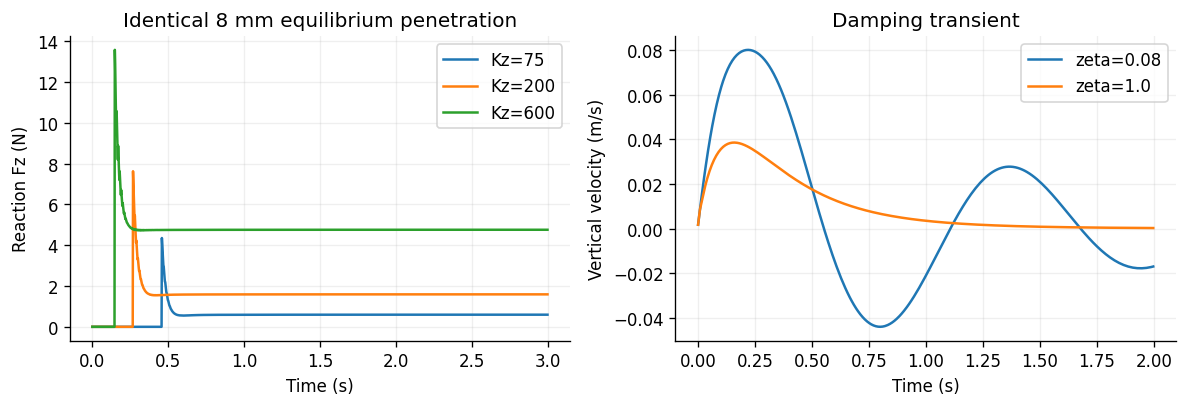

In [30]:
VALIDATION_PASSED=False
def controller_validation():
    rows=[]
    def record(name,condition,value):
        rows.append({'test':name,'status':'PASS' if condition else 'FAIL','key_value':str(value)})
    r=Robot(); r.reset(Q0); M,J,L,N=r.dynamics()
    record('Jacobian dimensions and finite',J.shape==(6,7) and np.isfinite(J).all(),J.shape)
    Jfd=np.zeros_like(J); q=r.d.qpos.copy(); p0,R0=r.pose()
    for i in range(7):
        qp=q.copy(); qp[i]+=1e-6; r.reset(qp); pp,RR=r.pose()
        Jfd[:,i]=np.r_[(pp-p0)/1e-6,rotation_error(RR,R0)/1e-6]
    r.reset(q)
    record('Jacobian finite differences',np.max(abs(J-Jfd))<1e-5,np.max(abs(J-Jfd)))
    eig=np.linalg.eigvalsh(M)
    record('Mass SPD/symmetric',M.shape==(7,7) and np.max(abs(M-M.T))<1e-10 and eig.min()>0,eig)
    record('Operational inertia regularized',np.isfinite(L).all() and np.linalg.eigvalsh(L).min()>0 and np.linalg.cond(L)<1e6,np.linalg.cond(L))
    for _ in range(500): r.apply_tau(r.gravity()); mujoco.mj_step(r.m,r.d)
    drift=np.linalg.norm(r.pose()[0]-p0)
    record('Gravity static drift <1 mm',drift<.001,drift)
    r.reset(Q0)
    directional=[]
    for axis in range(3):
        F=np.eye(6)[axis]; acceleration=J@np.linalg.solve(M,J.T@F)
        directional.append(acceleration[axis])
    # Virtual work equality supplements the directional acceleration check.
    dq=np.arange(7)/10; F=np.arange(6)/5
    record('J transpose wrench / virtual work',min(directional)>0 and abs((J.T@F)@dq-F@(J@dq))<1e-10,directional)
    clipped=r.apply_tau(np.ones(7)*1e4)
    record('Authoritative actuator clipping',np.allclose(clipped,r.limits[:,1]),clipped)
    r.reset(Q0); near_before=np.linalg.norm(r.d.qpos-Q0)
    # Excite the kinematic null direction, then regulate to q0 under a fixed Cartesian target.
    _,_,vh=np.linalg.svd(J); qnull=Q0+.12*vh[-1]; r.reset(qnull)
    target=r.pose()[0]; posture_before=np.linalg.norm(r.d.qpos-Q0)
    ctrl=Impedance(r)
    for i in range(500):
        if i%5==0: r.apply_tau(ctrl.torque(target,np.zeros(3)))
        mujoco.mj_step(r.m,r.d)
    displacement=np.linalg.norm(r.pose()[0]-target); posture_after=np.linalg.norm(r.d.qpos-Q0)
    record('Null-space posture and task leakage',posture_after<posture_before and displacement<.008,
           dict(before=posture_before,after=posture_after,ee_drift=displacement,leakage=np.linalg.norm(J@np.linalg.solve(M,N))))
    forces=[]; stiffness_traces=[]; sensor_samples=[]
    for kz in [75.,200.,600.]:
        r.reset(r.ik(np.array([.5,0,cfg.surface_z+cfg.probe_radius+.005]),Q0))
        ctrl=Impedance(r,[400,400,kz]); target=np.array([.5,0,cfg.surface_z+cfg.probe_radius-.008])
        f=[]
        for i in range(1500):
            if i%5==0: r.apply_tau(ctrl.torque(target,np.zeros(3)))
            mujoco.mj_step(r.m,r.d); f.append(r.external_wrench()[2])
            if i>1250 and kz==200:
                # Site force is child-on-parent, hence opposite external reaction (plus payload weight).
                sensor_samples.append((r.d.site_xmat[r.wrist].reshape(3,3)@r.d.sensordata[:3]).copy())
        forces.append(float(np.mean(f[-250:]))); stiffness_traces.append(f)
    record('Contact stiffness: low < medium < high',0<forces[0]<forces[1]<forces[2]<cfg.force_limit,forces)
    record('Force world +Z sign / plausible magnitude',forces[1]>0 and .2<forces[1]<5,forces[1])
    internal_mean=np.mean(sensor_samples,axis=0)
    record('Internal transducer / reconstructed external load',
           abs(internal_mean[2]+forces[1]-.08*9.81)<.5,internal_mean)
    damping_scores=[]; damping_traces=[]
    for zeta in [.08,1.]:
        r.reset(Q0); target=r.pose()[0]+[0,0,.02]; ctrl=Impedance(r,zeta=zeta); velocities=[]
        for i in range(1000):
            if i%5==0: r.apply_tau(ctrl.torque(target,np.zeros(3)))
            mujoco.mj_step(r.m,r.d); velocities.append(float((r.jacobian()@r.d.qvel)[2]))
        damping_scores.append(float(np.sqrt(np.mean(np.array(velocities)[500:]**2)))); damping_traces.append(velocities)
    record('Damping reduces residual oscillation',damping_scores[1]<damping_scores[0],damping_scores)
    workspace_ok=True; max_ik_error=0.
    for x in [.40,.50,.60]:
        for y in [-.14,0,.14]:
            for z in [.192,.30]:
                target=np.array([x,y,z]); q=r.ik(target,Q0); r.reset(q)
                max_ik_error=max(max_ik_error,np.linalg.norm(r.pose()[0]-target))
    for seed in range(100):
        s=scenario(seed)
        for t in np.linspace(0,6,30):
            xy,_=path_xy(s,t); workspace_ok &= .39<xy[0]<.61 and abs(xy[1])<.15
    record('Workspace reachability / trajectory bounds',workspace_ok and max_ik_error<.001,max_ik_error)
    env=PandaEnv(); check_env(env,warn=True,skip_render_check=True)
    obs,_=env.reset(seed=17)
    ratios=[]
    for action in [np.ones(3),-np.ones(3)]:
        before=env.ctrl.K.copy(); env.ctrl.adapt(action); ratios.extend(env.ctrl.K/before)
    record('Gym API, observations, action rate',env.observation_space.contains(obs) and min(ratios)>=1/1.2-1e-9 and max(ratios)<=1.2+1e-9,{'obs':obs.shape,'ratios':ratios})
    env.r.d.qpos[0]=np.nan
    obs,reward,terminated,truncated,info=env.step(np.zeros(3))
    record('Nonfinite state terminates with finite PPO input',terminated and np.isfinite(obs).all() and np.isfinite(reward),
           info['episode_metrics']['termination_reason'])
    env.close()
    # Nominal full contact episode validates all stepping levels and numerical state.
    s=scenario(91001,'validation',domain=False,index=1)
    m,trace=rollout(s)
    record('Full nominal contact episode / numerical safety',not m['safety'] and np.isfinite(trace.select_dtypes('number')).all().all(),m)
    record('Raw vs filtered sensor',trace.force_filtered.std()<=trace.force_raw.std()*1.2,
           {'raw_sd':trace.force_raw.std(),'filtered_sd':trace.force_filtered.std()})
    table=pd.DataFrame(rows); display(table)
    table.to_csv(OUT/'metrics/controller_validation.csv',index=False)
    trace.to_csv(OUT/'traces/controller_validation.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(10,3.5))
    for kz,f in zip([75,200,600],stiffness_traces): axs[0].plot(np.arange(len(f))*cfg.physics_dt,f,label=f'Kz={kz}')
    for z,v in zip([.08,1.],damping_traces): axs[1].plot(np.arange(len(v))*cfg.physics_dt,v,label=f'zeta={z}')
    axs[0].set(xlabel='Time (s)',ylabel='Reaction Fz (N)',title='Identical 8 mm equilibrium penetration')
    axs[1].set(xlabel='Time (s)',ylabel='Vertical velocity (m/s)',title='Damping transient')
    for ax in axs: ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(OUT/'plots/controller_validation.png',dpi=180); plt.show()
    if not (table.status=='PASS').all():
        raise RuntimeError('PRE-RL GATE FAILED: '+', '.join(table.loc[table.status=='FAIL','test'])+
                           '. Inspect validation traces; unsafe gains are FLAGGED. Training is blocked.')
    return True

VALIDATION_PASSED=controller_validation()

## 15. Classical baselines
Joint PD uses bounded damped-least-squares IK and feedforward joint velocity from successive targets. Fixed impedance uses constant gains. Scheduled impedance switches desired gains near contact and obeys the same stiffness rate bounds as PPO. Three sensible candidates per family are evaluated on a fixed seeded validation set. Selection is predeclared: minimize safety failures, then maximize success, then minimize normalized tracking+force error. This ranking is for validation selection only; final scientific reporting never collapses metrics into that score.

No ID/OOD seed enters tuning. PPO model selection uses the same robust validation scenarios. This is a modest, transparent baseline search, not an exhaustive claim of optimal classical control.

In [31]:
assert VALIDATION_PASSED, 'Run and pass every controller test before constructing training jobs.'
REQUESTED_PLAN=copy.deepcopy(PLAN)
if cfg.mode=='standard' and cfg.auto_runtime_budget:
    probe_start=time.perf_counter()
    _,probe_trace=rollout(scenario(91002,'validation',domain=False))
    probe_rate=len(probe_trace)/(time.perf_counter()-probe_start)
    if probe_rate<120:
        PLAN['n_val']=3
        print('Slow-CPU standard profile: three shared validation scenarios; use extended/full-budget mode for larger validation.')
VALIDATION_SCENARIOS=[scenario(200_000+i,'validation',index=i) for i in range(PLAN['n_val'])]
dump_json(OUT/'configs/validation_scenarios.json',[asdict(s) for s in VALIDATION_SCENARIOS])
def validation_rank(metrics):
    """Predeclared model-selection order. Final results always retain separate metrics."""
    df=pd.DataFrame(metrics)
    return (float(df.safety.mean()),-float(df.success.mean()),
            float(df.position_rmse.fillna(.25).mean()/.02+df.force_rmse.fillna(20).mean()/2))

def tune_baselines():
    candidates={
        'pd':[{'scale':x} for x in [.6,1.,1.5]],
        'fixed':[{'K':K,'zeta':z} for K,z in [((400,400,200),1.),((600,600,150),1.),((300,300,350),1.)]],
        'scheduled':[{'free_K':(650,650,450),'contact_K':K} for K in [(500,500,120),(600,600,200),(350,350,300)]]}
    selected={}; records=[]
    for method,configs in candidates.items():
        best=None
        for ci,params in enumerate(configs):
            metrics=[]
            for s in VALIDATION_SCENARIOS:
                m,_=rollout(s,method,params); metrics.append(m)
                records.append(dict(controller=method,candidate=ci,scenario=s.seed,params=json.dumps(params),**m))
            rank=validation_rank(metrics)
            if best is None or rank<best[0]: best=(rank,params)
        selected[method]=best[1]; print('Selected',method,best,flush=True)
    pd.DataFrame(records).to_csv(OUT/'metrics/baseline_validation.csv',index=False)
    dump_json(OUT/'configs/baselines.json',selected)
    return selected
BASELINES=tune_baselines()

Slow-CPU standard profile: three shared validation scenarios; use extended/full-budget mode for larger validation.
Selected pd ((0.0, -0.6666666666666666, 1.2820173553154581), {'scale': 1.5})
Selected fixed ((0.0, -0.6666666666666666, 1.2501054910099856), {'K': (300, 300, 350), 'zeta': 1.0})
Selected scheduled ((0.0, -0.6666666666666666, 1.243798770504025), {'free_K': (650, 650, 450), 'contact_K': (350, 350, 300)})


## 16. PPO adaptive impedance policy
SB3 PPO uses separate [256,256] tanh actor/critic MLPs, learning rate 3e−4, γ=.99, GAE=.95, clip=.2, entropy=.005, gradient norm=.5, normalized advantages, 256-step rollouts per environment, minibatches of 128, and five epochs. Two independent environments use DummyVecEnv to avoid notebook subprocess/pickling issues. Each PPO transition represents 50 ms of robot time.

Checkpoint directories contain weights, matching VecNormalize statistics, configuration, RNG snapshots and curriculum state. Atomic `latest.json`/`best.json` pointers only reference complete bundles. Resumption validates critical configuration, restores model/normalization/curriculum, and restarts new seeded episodes; partial rollout/environment physics is not restored, so continuation is **not bitwise identical** to uninterrupted training. Best-model statistics are saved with that specific model, never borrowed from a later checkpoint.

In [32]:
VARIANTS={'full':dict(domain=True,regularize=True,extended=None),
          'no_randomization':dict(domain=False,regularize=True,extended=None),
          'no_deltaK_cost':dict(domain=True,regularize=False,extended=None)}
if cfg.mode=='extended' and cfg.extended_experiments:
    VARIANTS.update(adaptive_KD=dict(domain=True,regularize=True,extended='damping'),
                    direct_torque=dict(domain=True,regularize=True,extended='torque'))

class ResearchCallback(BaseCallback):
    def __init__(self,run_dir,variant,seed,total,state=None):
        super().__init__(); self.run_dir=Path(run_dir); self.variant=variant; self.seed=seed; self.total=total
        state=state or {}; self.stage=state.get('stage',1); self.stage_started=state.get('stage_started',0)
        self.streak=state.get('streak',0); self.best_rank=tuple(state.get('best_rank',[float('inf')]*3))
        self.last_eval=state.get('last_eval',0); self.transitions=state.get('transitions',[])
        self.validations=state.get('validations',[]); self.episodes=[]; self.start_time=time.perf_counter()
        self.thresholds={1:.90,2:.85,3:.80}; self.pending_stage=None
    def state(self):
        return dict(stage=self.stage,stage_started=self.stage_started,streak=self.streak,
                    best_rank=self.best_rank,last_eval=self.last_eval,transitions=self.transitions,validations=self.validations,
                    steps=self.num_timesteps,seed=self.seed,variant=self.variant,total=self.total)
    def save_bundle(self,label):
        # Versioned complete directory, then atomic pointer. An interrupted write leaves previous bundle valid.
        dest=self.run_dir/f'{label}_{self.num_timesteps:09d}_{time.time_ns()}'; dest.mkdir(parents=True,exist_ok=True)
        self.model.save(dest/'model'); self.training_env.save(dest/'normalize.pkl')
        dump_json(dest/'state.json',self.state())
        torch.save({'python':random.getstate(),'numpy':np.random.get_state(),'torch':torch.get_rng_state()},dest/'rng.pt')
        dump_json(dest/'config.json',dict(config=asdict(cfg),variant=VARIANTS[self.variant],plan=PLAN))
        pointer=self.run_dir/f'{label}.json'; tmp=self.run_dir/f'{label}.tmp'
        dump_json(tmp,{'directory':dest.name}); os.replace(tmp,pointer)
    def _on_step(self):
        for info in self.locals['infos']:
            if 'episode_metrics' in info:
                row=dict(steps=self.num_timesteps,**info['episode_metrics'],
                         **{'reward_'+k:v for k,v in info['reward_components'].items()})
                self.episodes.append(row)
                with (self.run_dir/'episodes.jsonl').open('a') as f: f.write(json.dumps(row)+'\n')
                with (self.run_dir/'scenarios.jsonl').open('a') as f: f.write(json.dumps(info['scenario'])+'\n')
        return True
    def _on_rollout_end(self):
        due=self.num_timesteps-self.last_eval>=PLAN['eval_every']
        cap=max(cfg.rollout*cfg.n_envs,int(self.total*.20))
        fallback=self.stage<4 and self.num_timesteps-self.stage_started>=cap
        if due or fallback:
            # Shared robust validation distribution for all PPO variants and baselines.
            full=[]; curricular=[]
            for s in VALIDATION_SCENARIOS:
                m,_=rollout(s,'adaptive',model=self.model,norm=self.training_env,extended=VARIANTS[self.variant]['extended'])
                full.append(m)
                if self.stage<4:
                    easy=replace(s,height=0.,payload=.25,friction=.7,solref=cfg.contact_time_constant,push=(0.,0.,0.),noise=.02)
                    m,_=rollout(easy,'adaptive',model=self.model,norm=self.training_env,stage=self.stage,
                                extended=VARIANTS[self.variant]['extended']); curricular.append(m)
            rank=validation_rank(full); rate=float(np.mean([m['success'] for m in (curricular or full)]))
            self.last_eval=self.num_timesteps
            self.validations.append(dict(steps=self.num_timesteps,stage=self.stage,success=rate,
                                         robust_success=float(np.mean([m['success'] for m in full])),rank=rank))
            self.streak=self.streak+1 if rate>self.thresholds.get(self.stage,1.) else 0
            if rank<self.best_rank:
                self.best_rank=rank; self.save_bundle('best')
            if self.stage<4 and (self.streak>=PLAN['windows'] or fallback):
                reason='consecutive_validation_windows' if self.streak>=PLAN['windows'] else 'maximum_stage_steps'
                self.transitions.append(dict(steps=self.num_timesteps,old=self.stage,new=self.stage+1,reason=reason,success=rate))
                self.stage+=1; self.stage_started=self.num_timesteps; self.streak=0
                self.training_env.env_method('set_stage',self.stage)
                print(f'{self.variant}/{self.seed}: stage {self.stage}, {reason}',flush=True)
            self.save_bundle('latest')
            dump_json(self.run_dir/'curriculum.json',self.state())

def make_vec(variant,seed,stage=1):
    kwargs=VARIANTS[variant]
    vec=DummyVecEnv([lambda kw=kwargs: PandaEnv(stage=stage,**kw) for _ in range(cfg.n_envs)])
    vec.seed(seed); return vec

def bundle_dir(run_dir,label):
    pointer=Path(run_dir)/f'{label}.json'
    return Path(run_dir)/json.loads(pointer.read_text())['directory'] if pointer.exists() else None

def train_one(variant,seed,total):
    assert VALIDATION_PASSED,'Classical control gate has not passed.'
    seed_all(seed); run_dir=OUT/'checkpoints'/f'{variant}_seed{seed}'; run_dir.mkdir(parents=True,exist_ok=True)
    previous=bundle_dir(run_dir,'latest') if cfg.resume else None
    state=json.loads((previous/'state.json').read_text()) if previous else None
    if previous:
        saved=json.loads((previous/'config.json').read_text())
        critical=['physics_dt','control_dt','policy_dt','k_min','k_max','k_initial','force_integrator_gain','menagerie_commit']
        current=json.loads(json.dumps(asdict(cfg)))
        if any(saved['config'][k]!=current[k] for k in critical) or saved['variant']!=VARIANTS[variant]:
            raise ValueError('Resume configuration differs; use a new output directory.')
        vec=VecNormalize.load(previous/'normalize.pkl',make_vec(variant,seed,state['stage']))
        vec.training=True; vec.norm_reward=False
        model=PPO.load(previous/'model.zip',env=vec,device='cpu',force_reset=True)
        rng=torch.load(previous/'rng.pt',weights_only=False,map_location='cpu')
        random.setstate(rng['python']); np.random.set_state(rng['numpy']); torch.set_rng_state(rng['torch'])
        # Deterministic restart at new episode boundaries; not a bitwise replay of a partial rollout.
        vec.seed(seed+model.num_timesteps)
    else:
        vec=VecNormalize(make_vec(variant,seed),norm_obs=True,norm_reward=False,clip_obs=10.)
        model=PPO('MlpPolicy',vec,learning_rate=cfg.learning_rate,n_steps=cfg.rollout,batch_size=cfg.batch_size,
            n_epochs=cfg.epochs,gamma=cfg.gamma,gae_lambda=cfg.gae_lambda,clip_range=cfg.clip_range,
            ent_coef=cfg.ent_coef,max_grad_norm=cfg.max_grad_norm,normalize_advantage=True,
            policy_kwargs=dict(net_arch=dict(pi=[256,256],vf=[256,256]),activation_fn=torch.nn.Tanh),
            seed=seed,device='cpu',verbose=0)
    cb=ResearchCallback(run_dir,variant,seed,total,state)
    from stable_baselines3.common.logger import configure
    model.set_logger(configure(str(OUT/'logs'/f'{variant}_seed{seed}'/f'session_{time.time_ns()}'),['csv']))
    remaining=max(0,total-model.num_timesteps); start=time.perf_counter()
    if remaining:
        model.learn(total_timesteps=remaining,callback=cb,reset_num_timesteps=False)
        # Callback at rollout-end occurs before the final PPO gradient update; save final updated weights too.
        cb.num_timesteps=model.num_timesteps
        final=[rollout(s,'adaptive',model=model,norm=vec,extended=VARIANTS[variant]['extended'])[0] for s in VALIDATION_SCENARIOS]
        rank=validation_rank(final)
        if rank<cb.best_rank: cb.best_rank=rank; cb.save_bundle('best')
        cb.save_bundle('latest')
    print(f'{variant} seed {seed}: {model.num_timesteps:,} transitions; {time.perf_counter()-start:.1f} s this session',flush=True)
    vec.close(); return run_dir

def load_selected(run_dir):
    dest=bundle_dir(run_dir,'best') or bundle_dir(run_dir,'latest')
    state=json.loads((dest/'state.json').read_text()); variant=state['variant']
    vec=VecNormalize.load(dest/'normalize.pkl',make_vec(variant,state['seed'],4)); vec.training=False; vec.norm_reward=False
    return PPO.load(dest/'model.zip',device='cpu'),vec

## 17. Curriculum
Validation thresholds are >90% reaching, >85% force regulation and >80% contact tracking. Advancement requires multiple consecutive validation windows (2 debug; 3 standard/extended). A stage maximum of 20% of the run's step budget prevents indefinite stalls. This fallback is explicitly logged as `maximum_stage_steps`; it is **not** a successful mastery claim. New stage settings apply on reset, avoiding mid-episode task changes. Stage 4 receives the remaining budget.

Stage-specific validation reuses only validation seeds with nominal dynamics. Separately, robust stage-4 validation selects checkpoints for every method. Fixed small validation sets can be overfit; research extensions should enlarge them before freezing test sets.

## 18. Debug run and workload estimate
A complete classical rollout measures throughput. Installation, controller verification, tuning, frequent validation, disk I/O and rendering add overhead beyond the printed estimate. No claim of learning is inferred from this rollout.

In [33]:
start=time.perf_counter()
debug_metrics,debug_trace=rollout(replace(VALIDATION_SCENARIOS[0],push=(0.,0.,0.)))
seconds_per_episode=time.perf_counter()-start
transition_rate=len(debug_trace)/seconds_per_episode
if cfg.mode=='standard' and cfg.auto_runtime_budget:
    # Use only validation throughput, before generating any final test scenario.
    # Preserve meaningful per-run budgets; on a slow CPU prefer fewer independent seeds
    # to calling a tiny three-seed smoke test a trained benchmark.
    budget=max(60.,cfg.standard_minutes*60-(time.perf_counter()-PROJECT_STARTED))
    variants=len(VARIANTS)
    def minimum_cost(nseeds):
        j=nseeds*variants
        return (j*cfg.min_standard_steps/transition_rate*1.3+
                (20*(3+j)*2+j*32*PLAN['n_val'])*seconds_per_episode+180)
    if minimum_cost(3)>budget:
        PLAN['seeds']=PLAN['seeds'][:1]
    j=len(PLAN['seeds'])*variants
    PLAN['n_test']=int(np.clip(.20*budget/((3+j)*2*seconds_per_episode),10,100))
    reserved=((3+j)*2*PLAN['n_test']+j*32*PLAN['n_val'])*seconds_per_episode+180
    affordable=int(max(0,budget-reserved)*transition_rate/(1.3*j))
    block=cfg.rollout*cfg.n_envs
    PLAN['steps']=min(PLAN['steps'],max(cfg.min_standard_steps,(affordable//block)*block))
    PLAN['eval_every']=max(block,int(PLAN['steps']*.05)//block*block)
    print('Hardware-aware standard plan:',PLAN)
    print('Requested plan:',REQUESTED_PLAN)
    print('Any one-seed result is exploratory; disable auto_runtime_budget for the full three-seed/100-case protocol.')
    dump_json(OUT/'configs/budget_adjustment.json',dict(requested=REQUESTED_PLAN,executed=PLAN,
              reason='validation-only throughput estimate',available_seconds=budget))
    dump_json(OUT/'configs/config.json',dict(config=asdict(cfg),plan=PLAN))
jobs=len(VARIANTS)*len(PLAN['seeds'])
eval_episodes=(3+jobs)*2*PLAN['n_test']
estimated_seconds=(jobs*PLAN['steps']/transition_rate*1.3 + eval_episodes*seconds_per_episode)
print(f'Measured single-environment throughput: {transition_rate:.1f} policy transitions/s')
print(f'Planned: {jobs} PPO runs, {jobs*PLAN["steps"]:,} training transitions, {eval_episodes} ID/OOD episodes.')
print(f'Lower-order wall-clock estimate incl. 30% training overhead: {estimated_seconds/60:.1f} minutes; validation/video extra.')
print('Debug is a pipeline check, not evidence of convergence. Standard targets one hour but may exceed it on slow CPUs.')
dump_json(OUT/'configs/workload.json',dict(transition_rate=transition_rate,estimated_seconds=estimated_seconds,
                                        jobs=jobs,train_steps=PLAN['steps'],evaluation_episodes=eval_episodes))

Hardware-aware standard plan: {'seeds': [11], 'steps': 32768, 'n_test': 20, 'n_val': 3, 'eval_every': 1536, 'windows': 3}
Requested plan: {'seeds': [11, 29, 47], 'steps': 100352, 'n_test': 100, 'n_val': 9, 'eval_every': 4096, 'windows': 3}
Any one-seed result is exploratory; disable auto_runtime_budget for the full three-seed/100-case protocol.
Measured single-environment throughput: 77.0 policy transitions/s
Planned: 3 PPO runs, 98,304 training transitions, 240 ID/OOD episodes.
Lower-order wall-clock estimate incl. 30% training overhead: 38.0 minutes; validation/video extra.
Debug is a pipeline check, not evidence of convergence. Standard targets one hour but may exceed it on slow CPUs.


## 19. Training (selected mode)
This executes all required A/B/C runs with the same budget per seed. In extended mode it also trains adaptive K+D and direct residual-torque PPO. Interruptions can be resumed by rerunning the notebook with the same mode/output directory and `resume=True`.

In [34]:
TRAINING_START=time.perf_counter()
RUNS={}
for variant in VARIANTS:
    for seed in PLAN['seeds']:
        RUNS[(variant,seed)]=train_one(variant,seed,PLAN['steps'])
TRAINING_SECONDS=time.perf_counter()-TRAINING_START
print('Total training elapsed minutes:',TRAINING_SECONDS/60)

full/11: stage 2, consecutive_validation_windows


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


full/11: stage 3, maximum_stage_steps


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


full/11: stage 4, maximum_stage_steps
full seed 11: 32,768 transitions; 759.9 s this session
no_randomization/11: stage 2, consecutive_validation_windows


...

no_randomization/11: stage 4, maximum_stage_steps
no_randomization seed 11: 32,768 transitions; 867.1 s this session
no_deltaK_cost/11: stage 2, consecutive_validation_windows


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


no_deltaK_cost/11: stage 3, maximum_stage_steps


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


no_deltaK_cost/11: stage 4, maximum_stage_steps
no_deltaK_cost seed 11: 32,768 transitions; 752.0 s this session
Total training elapsed minutes: 39.65936156511667


## 20. Paired ID evaluation
Only after all model/baseline selections are frozen do we generate test cases from `SPLIT_BASES`. Debug, standard and extended use disjoint test-seed namespaces, so a debug demonstration does not expose the final standard test set. Training scenario seeds are at least one billion; validation and all test namespaces are below that boundary. ID includes balanced force targets 3,5,7 N. Every controller receives identical scenario parameters and disturbance/noise streams. PPO actions are deterministic and observation statistics frozen. Traces are saved as compressed CSV; episode metrics are saved incrementally.

In [35]:
# Test scenarios are materialized only after model and baseline selection are frozen.
TEST_SCENARIOS={split:[scenario(SPLIT_BASES[split]+i,split,index=i) for i in range(PLAN['n_test'])]
                for split in ['ID','OOD']}
for split,scenarios in TEST_SCENARIOS.items(): dump_json(OUT/f'configs/{split}_scenarios.json',[asdict(s) for s in scenarios])
METHODS={name:dict(controller=name,params=params,run_dir=None,extended=None,seed=-1)
         for name,params in BASELINES.items()}
for (variant,seed),directory in RUNS.items():
    METHODS[f'PPO_{variant}_s{seed}']=dict(controller='adaptive',params=None,run_dir=directory,
                                          extended=VARIANTS[variant]['extended'],seed=seed)
ALL_METRICS=[]
def evaluate_suite(split,scenarios):
    for name,method in METHODS.items():
        model=norm=None
        if method['run_dir']: model,norm=load_selected(method['run_dir'])
        for idx,s in enumerate(scenarios):
            m,trace=rollout(s,method['controller'],method['params'],model,norm,extended=method['extended'])
            row=dict(controller=name,family=name.rsplit('_s',1)[0] if name.startswith('PPO_') else name,
                     training_seed=method['seed'],split=split,scenario=s.seed,shift=s.shift,**m)
            ALL_METRICS.append(row)
            trace.to_csv(OUT/'traces'/f'{split}_{name}_{s.seed}.csv.gz',index=False,compression='gzip')
        if norm is not None: norm.close()
        pd.DataFrame(ALL_METRICS).to_csv(OUT/'metrics/episodes.csv',index=False)
        print('Evaluated',split,name,flush=True)

In [36]:
evaluate_suite('ID',TEST_SCENARIOS['ID'])

Evaluated ID pd
Evaluated ID fixed
Evaluated ID scheduled
Evaluated ID PPO_full_s11
Evaluated ID PPO_no_randomization_s11
Evaluated ID PPO_no_deltaK_cost_s11


## 21. OOD evaluation
Stratified shifts include figure-eight geometry, 0.55–0.8 kg payload, friction 0.2/1.25, solver-compliance time constant 0.08 s, 10 N disturbances, and combinations. These are outside the declared training ranges. Debug's three cases cannot cover every shift; standard and extended cycle through all six. Optional 8–9 N target extrapolation is deliberately excluded unless separately validated; it is not necessary to label these other shifts OOD. Negative OOD outcomes are retained.

In [37]:
evaluate_suite('OOD',TEST_SCENARIOS['OOD'])

Evaluated OOD pd
Evaluated OOD fixed
Evaluated OOD scheduled
Evaluated OOD PPO_full_s11
Evaluated OOD PPO_no_randomization_s11
Evaluated OOD PPO_no_deltaK_cost_s11


## 22. Disturbance benchmark
Standardized 200 ms pushes start at 6 s, along ±X/±Y, with 2,5,8 N magnitudes. Normal-direction disturbances are omitted because safe force margins depend on the contact case. All controllers share all cases. Recovery begins after pulse end and requires both <2 cm position error and <2 N force error continuously for 300 ms. Non-recovery is censored/missing and has a separately reported failure rate. Maximum excursion is measured from onset onward.

In [38]:
DISTURBANCE_SCENARIOS=[]
for i,(axis,mag) in enumerate((axis,mag) for axis in [(1,0,0),(-1,0,0),(0,1,0),(0,-1,0)] for mag in [2.,5.,8.]):
    s=scenario(SPLIT_BASES['disturbance']+i,'disturbance',domain=False)
    DISTURBANCE_SCENARIOS.append(replace(s,force=5.,push=tuple(np.array(axis)*mag),push_start=6.,push_duration=.2))
if cfg.mode=='debug': DISTURBANCE_SCENARIOS=DISTURBANCE_SCENARIOS[::4]
dump_json(OUT/'configs/disturbance_scenarios.json',[asdict(s) for s in DISTURBANCE_SCENARIOS])
evaluate_suite('disturbance',DISTURBANCE_SCENARIOS)
RESULTS=pd.DataFrame(ALL_METRICS)

Evaluated disturbance pd
Evaluated disturbance fixed
Evaluated disturbance scheduled
Evaluated disturbance PPO_full_s11
Evaluated disturbance PPO_no_randomization_s11
Evaluated disturbance PPO_no_deltaK_cost_s11


## 23. Ablations
All required variants have already been trained and now use the same ID/OOD/disturbance evaluation:

| Variant | Changed factor | Retained controls |
|---|---|---|
| Full | None | Complete curriculum and randomized dynamics |
| No randomization | Nominal dynamics and no training pushes | Procedural lines/circles, target-force variation |
| No ΔK cost | Removes reward regularization only | Hard stiffness bounds and per-action rate limit |
| Adaptive K+D (extended) | Adds log damping multipliers in [0.5,2] | Nominal inertia-derived damping and torque limits |
| Direct torque (extended) | 7 normalized residual torques at 20 Hz | Gravity compensation and identical task/safety |

The torque extension is explicitly **residual torque plus gravity**, not a policy forced to learn arm weight support. It has a different action bandwidth/dimension, which limits H4's interpretation. No null-space or impedance wrench is added to its output. Desired force/path remain observable. Compare validation learning curves against total policy transitions and final safety/smoothness at matched budgets.

## 24. Statistical analysis and result tables
Each method receives paired scenarios. Means, SDs, available counts and 95% **crossed bootstrap** confidence intervals resample training seeds and scenario IDs independently, avoiding treatment of every seed–episode row as independent. Three seeds still give imprecise seed-level uncertainty. Debug's one-seed interval represents scenario uncertainty only. Binary all-success/all-failure bootstrap intervals may degenerate and should not be interpreted as certainty about unseen trials.

Paired differences align scenario and training seed for PPO ablations; deterministic baselines are paired to each true PPO seed. Paired standardized effect sizes are descriptive. Intervals are exploratory and not corrected for multiple comparisons. Missing recovery values and premature stops are never imputed as successful recovery or zero error; inspect missing counts and failure tables. The notebook does not invent benchmark numbers.

In [39]:
METRICS=['success','position_rmse','force_rmse','physical_force_rmse','peak_force','recovery_time','recovery_failure',
         'jerk','control_effort','safety','completion','work_proxy','overshoot','settling_time']
def hierarchical_interval(group,metric,B=None):
    """Crossed bootstrap: resample training seeds and paired scenario IDs independently.
    Classical baselines have one deterministic row; no fictitious training seeds added.
    Missing continuous metrics stay missing; report available count and failures separately.
    """
    B=B or cfg.bootstrap
    matrix=group.pivot(index='training_seed',columns='scenario',values=metric).astype(float).to_numpy()
    values=matrix[np.isfinite(matrix)]
    if not len(values): return dict(mean=np.nan,sd=np.nan,ci_low=np.nan,ci_high=np.nan,n=0)
    rng=np.random.default_rng(cfg.seed); estimates=[]
    for _ in range(B):
        sampled=matrix[np.ix_(rng.integers(matrix.shape[0],size=matrix.shape[0]),rng.integers(matrix.shape[1],size=matrix.shape[1]))]
        if np.isfinite(sampled).any(): estimates.append(float(np.nanmean(sampled)))
    return dict(mean=float(values.mean()),sd=float(values.std(ddof=1)) if len(values)>1 else np.nan,
                ci_low=float(np.quantile(estimates,.025)),ci_high=float(np.quantile(estimates,.975)),n=len(values))
summary=[]
for (split,family),group in RESULTS.groupby(['split','family']):
    for metric in METRICS: summary.append(dict(split=split,controller=family,metric=metric,**hierarchical_interval(group,metric)))
SUMMARY=pd.DataFrame(summary); SUMMARY.to_csv(OUT/'metrics/summary_numeric.csv',index=False)
for split in ['ID','OOD','disturbance']:
    sub=SUMMARY[SUMMARY.split==split].copy()
    sub['estimate']=sub.apply(lambda r:f'{r["mean"]:.3g} Â± {r.sd:.3g} [{r.ci_low:.3g}, {r.ci_high:.3g}] (n={r.n})',axis=1)
    table=sub.pivot(index='controller',columns='metric',values='estimate')
    table.to_csv(OUT/f'metrics/{split}_table.csv'); print(split,'mean Â± SD [95% bootstrap CI]'); display(table)
    table.loc[table.index.str.startswith('PPO')].to_csv(OUT/f'metrics/{split}_ablations.csv')

paired=[]
for split in ['ID','OOD','disturbance']:
    for comparator in ['fixed','scheduled','pd','PPO_no_randomization','PPO_no_deltaK_cost','PPO_adaptive_KD','PPO_direct_torque']:
        for metric in ['position_rmse','force_rmse','success','safety','recovery_time','jerk','control_effort']:
            a=RESULTS[(RESULTS.split==split)&(RESULTS.family=='PPO_full')]
            b=RESULTS[(RESULTS.split==split)&(RESULTS.family==comparator)]
            if b.empty: continue
            # Classical reference replicated across true PPO training seeds only for a paired difference.
            if comparator.startswith('PPO'):
                merged=a.merge(b,on=['scenario','training_seed'],suffixes=('_a','_b'))
            else: merged=a.merge(b[['scenario',metric]],on='scenario',suffixes=('_a','_b'))
            merged[metric]=merged[metric+'_a'].astype(float)-merged[metric+'_b'].astype(float)
            interval=hierarchical_interval(merged,metric)
            d=merged[metric].dropna()
            paired.append(dict(split=split,comparator=comparator,metric=metric,**interval,
                               paired_dz=float(d.mean()/d.std(ddof=1)) if len(d)>1 and d.std()>0 else np.nan))
PAIRED=pd.DataFrame(paired); PAIRED.to_csv(OUT/'metrics/paired_effects.csv',index=False)
print('Paired effects = PPO full minus comparator. Lower is better except success. CIs are exploratory, not multiplicity-adjusted.')
display(PAIRED)
RESULTS.groupby(['split','family','termination_reason']).size().rename('count').to_csv(OUT/'metrics/failures.csv')

ID mean Â± SD [95% bootstrap CI]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


metric,completion,control_effort,force_rmse,jerk,overshoot,peak_force,physical_force_rmse,position_rmse,recovery_failure,recovery_time,safety,settling_time,success,work_proxy
controller,,,,,,,,,,,,,,
PPO_full,"0.902 Â± 0.243 [0.782, 1] (n=20)","1.09e+04 Â± 2.29e+03 [9.8e+03, 1.18e+04] (n=20)","1.12 Â± 0.801 [0.8, 1.48] (n=20)","18 Â± 57.8 [4.18, 44.2] (n=20)","9.89 Â± 4.08 [8.18, 11.6] (n=20)","14.8 Â± 3.91 [13.1, 16.5] (n=20)","3.34 Â± 1.28 [2.81, 3.9] (n=20)","0.018 Â± 0.00522 [0.0158, 0.02] (n=20)","0.2 Â± 0.41 [0.05, 0.4] (n=20)","0.494 Â± 0.728 [0.18, 0.877] (n=16)","0.15 Â± 0.366 [0, 0.35] (n=20)","0.455 Â± 0.909 [0.128, 0.932] (n=19)","0.45 Â± 0.51 [0.25, 0.65] (n=20)","27.2 Â± 7.87 [23.8, 30.4] (n=20)"
PPO_no_deltaK_cost,"0.918 Â± 0.211 [0.812, 0.996] (n=20)","1.09e+04 Â± 2.13e+03 [9.94e+03, 1.18e+04] (n=20)","1.09 Â± 0.726 [0.8, 1.42] (n=20)","5.82 Â± 4.83 [4.05, 8.08] (n=20)","10 Â± 4.16 [8.28, 11.8] (n=20)","14.9 Â± 4 [13.2, 16.7] (n=20)","3.4 Â± 1.35 [2.85, 4.01] (n=20)","0.0185 Â± 0.00532 [0.0163, 0.0207] (n=20)","0.15 Â± 0.366 [0, 0.3] (n=20)","0.466 Â± 0.712 [0.172, 0.819] (n=17)","0.2 Â± 0.41 [0.05, 0.4] (n=20)","0.658 Â± 1.22 [0.195, 1.26] (n=20)","0.45 Â± 0.51 [0.25, 0.65] (n=20)","27.4 Â± 7.52 [24.2, 30.5] (n=20)"
PPO_no_randomization,"0.902 Â± 0.243 [0.782, 1] (n=20)","1.09e+04 Â± 2.29e+03 [9.8e+03, 1.18e+04] (n=20)","1.12 Â± 0.801 [0.8, 1.48] (n=20)","18 Â± 57.8 [4.18, 44.2] (n=20)","9.89 Â± 4.08 [8.18, 11.6] (n=20)","14.8 Â± 3.91 [13.1, 16.5] (n=20)","3.34 Â± 1.28 [2.81, 3.9] (n=20)","0.018 Â± 0.00522 [0.0158, 0.02] (n=20)","0.2 Â± 0.41 [0.05, 0.4] (n=20)","0.494 Â± 0.728 [0.18, 0.877] (n=16)","0.15 Â± 0.366 [0, 0.35] (n=20)","0.455 Â± 0.909 [0.128, 0.932] (n=19)","0.45 Â± 0.51 [0.25, 0.65] (n=20)","27.2 Â± 7.87 [23.8, 30.4] (n=20)"
fixed,"0.912 Â± 0.214 [0.807, 0.987] (n=20)","1.08e+04 Â± 2.05e+03 [9.84e+03, 1.17e+04] (n=20)","0.767 Â± 0.483 [0.566, 0.988] (n=20)","6.05 Â± 3.95 [4.44, 7.8] (n=20)","10.1 Â± 3.77 [8.47, 11.7] (n=20)","15 Â± 3.64 [13.4, 16.6] (n=20)","3.37 Â± 1.19 [2.87, 3.89] (n=20)","0.016 Â± 0.00488 [0.0139, 0.0181] (n=20)","0.15 Â± 0.366 [0, 0.3] (n=20)","0.55 Â± 0.828 [0.227, 0.983] (n=17)","0.2 Â± 0.41 [0.05, 0.4] (n=20)","0.235 Â± 0.401 [0.0824, 0.415] (n=20)","0.6 Â± 0.503 [0.4, 0.8] (n=20)","28.1 Â± 8.86 [24.4, 31.8] (n=20)"
pd,"0.831 Â± 0.336 [0.664, 0.956] (n=20)","1.02e+04 Â± 3.08e+03 [8.75e+03, 1.15e+04] (n=20)","1.01 Â± 0.527 [0.789, 1.24] (n=18)","6.12 Â± 4.75 [4.16, 8.3] (n=18)","11.9 Â± 4.31 [10.1, 13.8] (n=20)","16.8 Â± 4.05 [15.1, 18.6] (n=20)","3.4 Â± 1.07 [2.93, 3.89] (n=18)","0.0156 Â± 0.00506 [0.0135, 0.018] (n=18)","0.3 Â± 0.47 [0.1, 0.5] (n=20)","0.885 Â± 1.17 [0.332, 1.51] (n=14)","0.25 Â± 0.444 [0.0988, 0.45] (n=20)","0.128 Â± 0.25 [0.0289, 0.255] (n=18)","0.55 Â± 0.51 [0.3, 0.75] (n=20)","29 Â± 10.2 [24.7, 33.5] (n=20)"
scheduled,"0.905 Â± 0.222 [0.797, 0.984] (n=20)","1.08e+04 Â± 2.08e+03 [9.82e+03, 1.17e+04] (n=20)","0.807 Â± 0.461 [0.614, 1.01] (n=20)","5.53 Â± 3.45 [4.15, 7.04] (n=20)","10.2 Â± 3.82 [8.59, 11.8] (n=20)","15.1 Â± 3.61 [13.6, 16.7] (n=20)","3.43 Â± 1.17 [2.94, 3.95] (n=20)","0.0151 Â± 0.00484 [0.013, 0.0171] (n=20)","0.15 Â± 0.366 [0, 0.3] (n=20)","0.315 Â± 0.544 [0.0863, 0.595] (n=17)","0.2 Â± 0.41 [0.05, 0.4] (n=20)","0.27 Â± 0.446 [0.0974, 0.475] (n=20)","0.6 Â± 0.503 [0.4, 0.8] (n=20)","28.2 Â± 8.94 [24.5, 32.1] (n=20)"


OOD mean Â± SD [95% bootstrap CI]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

metric,completion,control_effort,force_rmse,jerk,overshoot,peak_force,physical_force_rmse,position_rmse,recovery_failure,recovery_time,safety,settling_time,success,work_proxy
controller,,,,,,,,,,,,,,
PPO_full,"1 Â± 0 [1, 1] (n=12)","1.15e+04 Â± 681 [1.11e+04, 1.18e+04] (n=12)","0.843 Â± 0.334 [0.644, 1.02] (n=12)","3.99 Â± 1.63 [3.11, 4.96] (n=12)","10.3 Â± 1.49 [9.51, 11.1] (n=12)","15.3 Â± 1.49 [14.5, 16.1] (n=12)","3.46 Â± 0.732 [3.03, 3.88] (n=12)","0.0137 Â± 0.00576 [0.0108, 0.0169] (n=12)","0.0833 Â± 0.289 [0, 0.25] (n=12)","0.168 Â± 0.376 [0, 0.404] (n=11)","0 Â± 0 [0, 0] (n=12)","0.171 Â± 0.209 [0.0625, 0.283] (n=12)","0.917 Â± 0.289 [0.75, 1] (n=12)","25.9 Â± 7.79 [21.8, 30.3] (n=12)"
PPO_no_deltaK_cost,"1 Â± 0 [1, 1] (n=12)","1.15e+04 Â± 680 [1.11e+04, 1.18e+04] (n=12)","0.84 Â± 0.315 [0.648, 1] (n=12)","4.04 Â± 1.62 [3.15, 4.97] (n=12)","10.2 Â± 1.54 [9.45, 11.1] (n=12)","15.2 Â± 1.54 [14.4, 16.1] (n=12)","3.46 Â± 0.688 [3.06, 3.86] (n=12)","0.0138 Â± 0.00589 [0.0108, 0.0171] (n=12)","0.0833 Â± 0.289 [0, 0.25] (n=12)","0.168 Â± 0.376 [0, 0.404] (n=11)","0 Â± 0 [0, 0] (n=12)","0.171 Â± 0.209 [0.0625, 0.283] (n=12)","0.917 Â± 0.289 [0.75, 1] (n=12)","25.9 Â± 7.8 [21.8, 30.3] (n=12)"
PPO_no_randomization,"1 Â± 0 [1, 1] (n=12)","1.15e+04 Â± 681 [1.11e+04, 1.18e+04] (n=12)","0.843 Â± 0.334 [0.644, 1.02] (n=12)","3.99 Â± 1.63 [3.11, 4.96] (n=12)","10.3 Â± 1.49 [9.51, 11.1] (n=12)","15.3 Â± 1.49 [14.5, 16.1] (n=12)","3.46 Â± 0.732 [3.03, 3.88] (n=12)","0.0137 Â± 0.00576 [0.0108, 0.0169] (n=12)","0.0833 Â± 0.289 [0, 0.25] (n=12)","0.168 Â± 0.376 [0, 0.404] (n=11)","0 Â± 0 [0, 0] (n=12)","0.171 Â± 0.209 [0.0625, 0.283] (n=12)","0.917 Â± 0.289 [0.75, 1] (n=12)","25.9 Â± 7.79 [21.8, 30.3] (n=12)"
fixed,"1 Â± 0 [1, 1] (n=12)","1.14e+04 Â± 629 [1.11e+04, 1.17e+04] (n=12)","0.655 Â± 0.311 [0.493, 0.839] (n=12)","4.1 Â± 1.74 [3.2, 5.1] (n=12)","10.8 Â± 1.77 [9.96, 11.9] (n=12)","15.8 Â± 1.77 [15, 16.9] (n=12)","3.72 Â± 0.745 [3.31, 4.15] (n=12)","0.00954 Â± 0.0013 [0.00887, 0.0103] (n=12)","0 Â± 0 [0, 0] (n=12)","0 Â± 0 [0, 0] (n=12)","0 Â± 0 [0, 0] (n=12)","2.22e-16 Â± 0 [2.22e-16, 2.22e-16] (n=12)","1 Â± 0 [1, 1] (n=12)","26.1 Â± 8.2 [21.7, 30.8] (n=12)"
pd,"1 Â± 0 [1, 1] (n=12)","1.16e+04 Â± 636 [1.12e+04, 1.19e+04] (n=12)","0.909 Â± 0.314 [0.734, 1.09] (n=12)","4.73 Â± 2.51 [3.54, 6.21] (n=12)","12.9 Â± 0.827 [12.4, 13.3] (n=12)","17.9 Â± 0.827 [17.4, 18.3] (n=12)","4.12 Â± 0.813 [3.69, 4.58] (n=12)","0.00927 Â± 0.00143 [0.00848, 0.01] (n=12)","0 Â± 0 [0, 0] (n=12)","0.137 Â± 0.181 [0.05, 0.246] (n=12)","0 Â± 0 [0, 0] (n=12)","2.22e-16 Â± 0 [2.22e-16, 2.22e-16] (n=12)","1 Â± 0 [1, 1] (n=12)","30 Â± 9.73 [24.6, 35.4] (n=12)"
scheduled,"1 Â± 0 [1, 1] (n=12)","1.14e+04 Â± 633 [1.11e+04, 1.18e+04] (n=12)","0.737 Â± 0.312 [0.576, 0.926] (n=12)","4.53 Â± 1.71 [3.62, 5.54] (n=12)","10.8 Â± 1.86 [9.91, 11.9] (n=12)","15.8 Â± 1.86 [14.9, 16.9] (n=12)","3.75 Â± 0.729 [3.35, 4.17] (n=12)","0.00836 Â± 0.0011 [0.00779, 0.00897] (n=12)","0 Â± 0 [0, 0] (n=12)","0 Â± 0 [0, 0] (n=12)","0 Â± 0 [0, 0] (n=12)","0.1 Â± 0 [0.1, 0.1] (n=12)","1 Â± 0 [1, 1] (n=12)","26.7 Â± 8.45 [22.1, 31.4] (n=12)"


Paired effects = PPO full minus comparator. Lower is better except success. CIs are exploratory, not multiplicity-adjusted.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,split,comparator,metric,mean,sd,ci_low,ci_high,n,paired_dz
0,ID,fixed,position_rmse,0.001977,0.003861,0.000440,0.003589,20,0.512188
1,ID,fixed,force_rmse,0.351122,0.593892,0.130789,0.643164,20,0.591222
2,ID,fixed,success,-0.150000,0.489360,-0.350000,0.050000,20,-0.306523
3,ID,fixed,safety,-0.050000,0.394034,-0.201250,0.100000,20,-0.126892
4,ID,fixed,recovery_time,-0.006667,0.916879,-0.496435,0.446953,15,-0.007271
...,...,...,...,...,...,...,...,...,...
100,disturbance,PPO_no_deltaK_cost,success,0.000000,0.000000,0.000000,0.000000,12,NaN
101,disturbance,PPO_no_deltaK_cost,safety,0.000000,0.000000,0.000000,0.000000,12,NaN
102,disturbance,PPO_no_deltaK_cost,recovery_time,0.000000,0.000000,0.000000,0.000000,11,NaN
103,disturbance,PPO_no_deltaK_cost,jerk,-0.046917,0.355042,-0.238389,0.145830,12,-0.132146


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 25. Publication-style visualizations
Figures are saved as PNG and vector PDF. Representative cases are selected by seed before looking at outcomes. Benchmark uncertainty is shown alongside separate safety and success rates; recovery failure is plotted with recovery time.

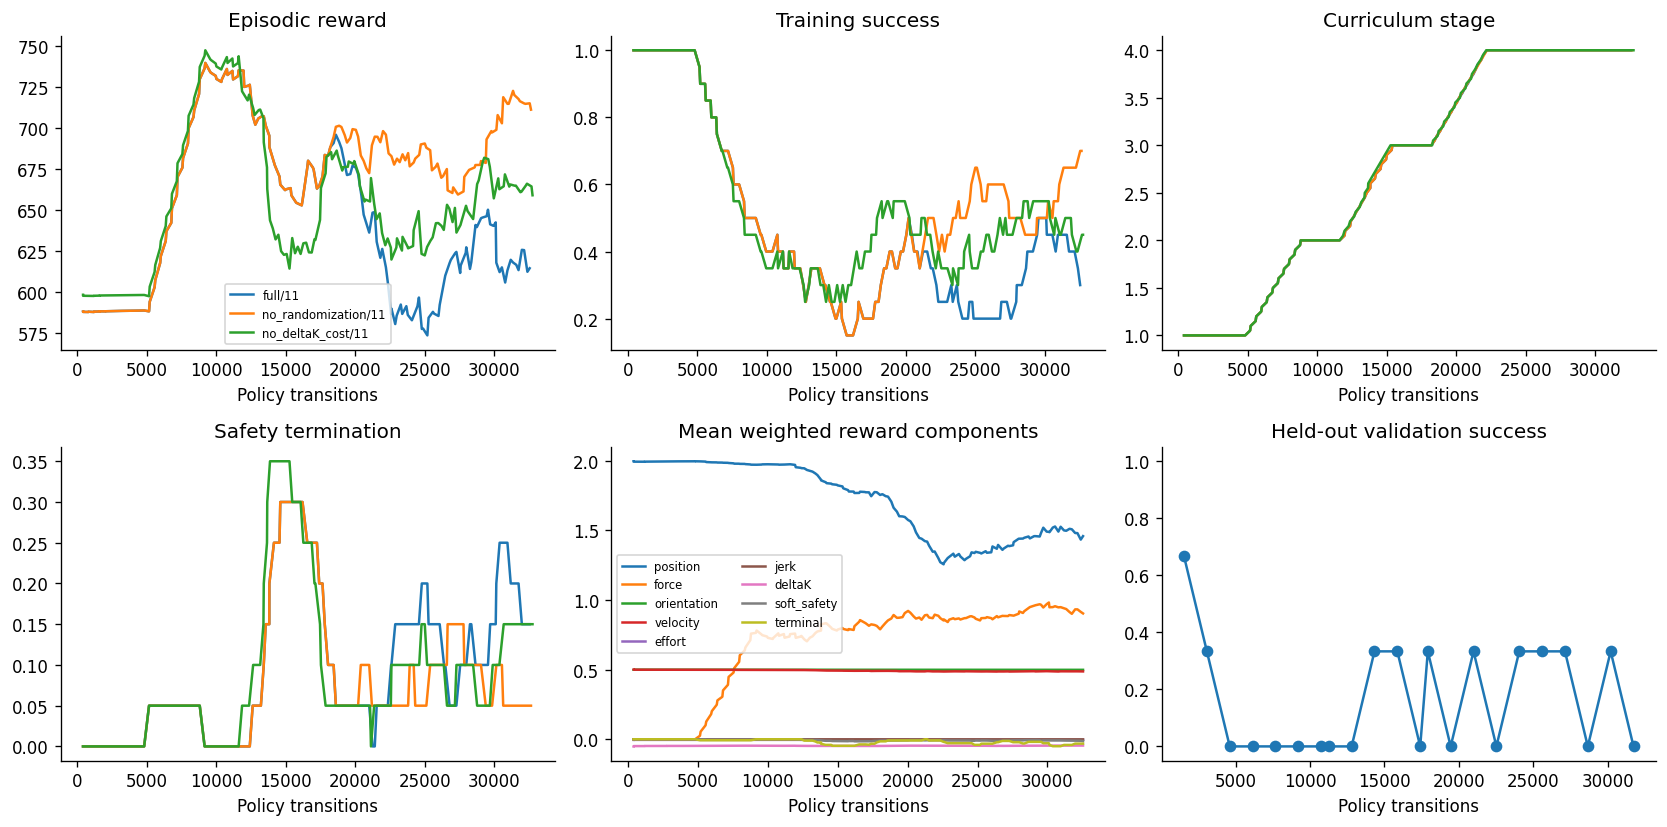

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


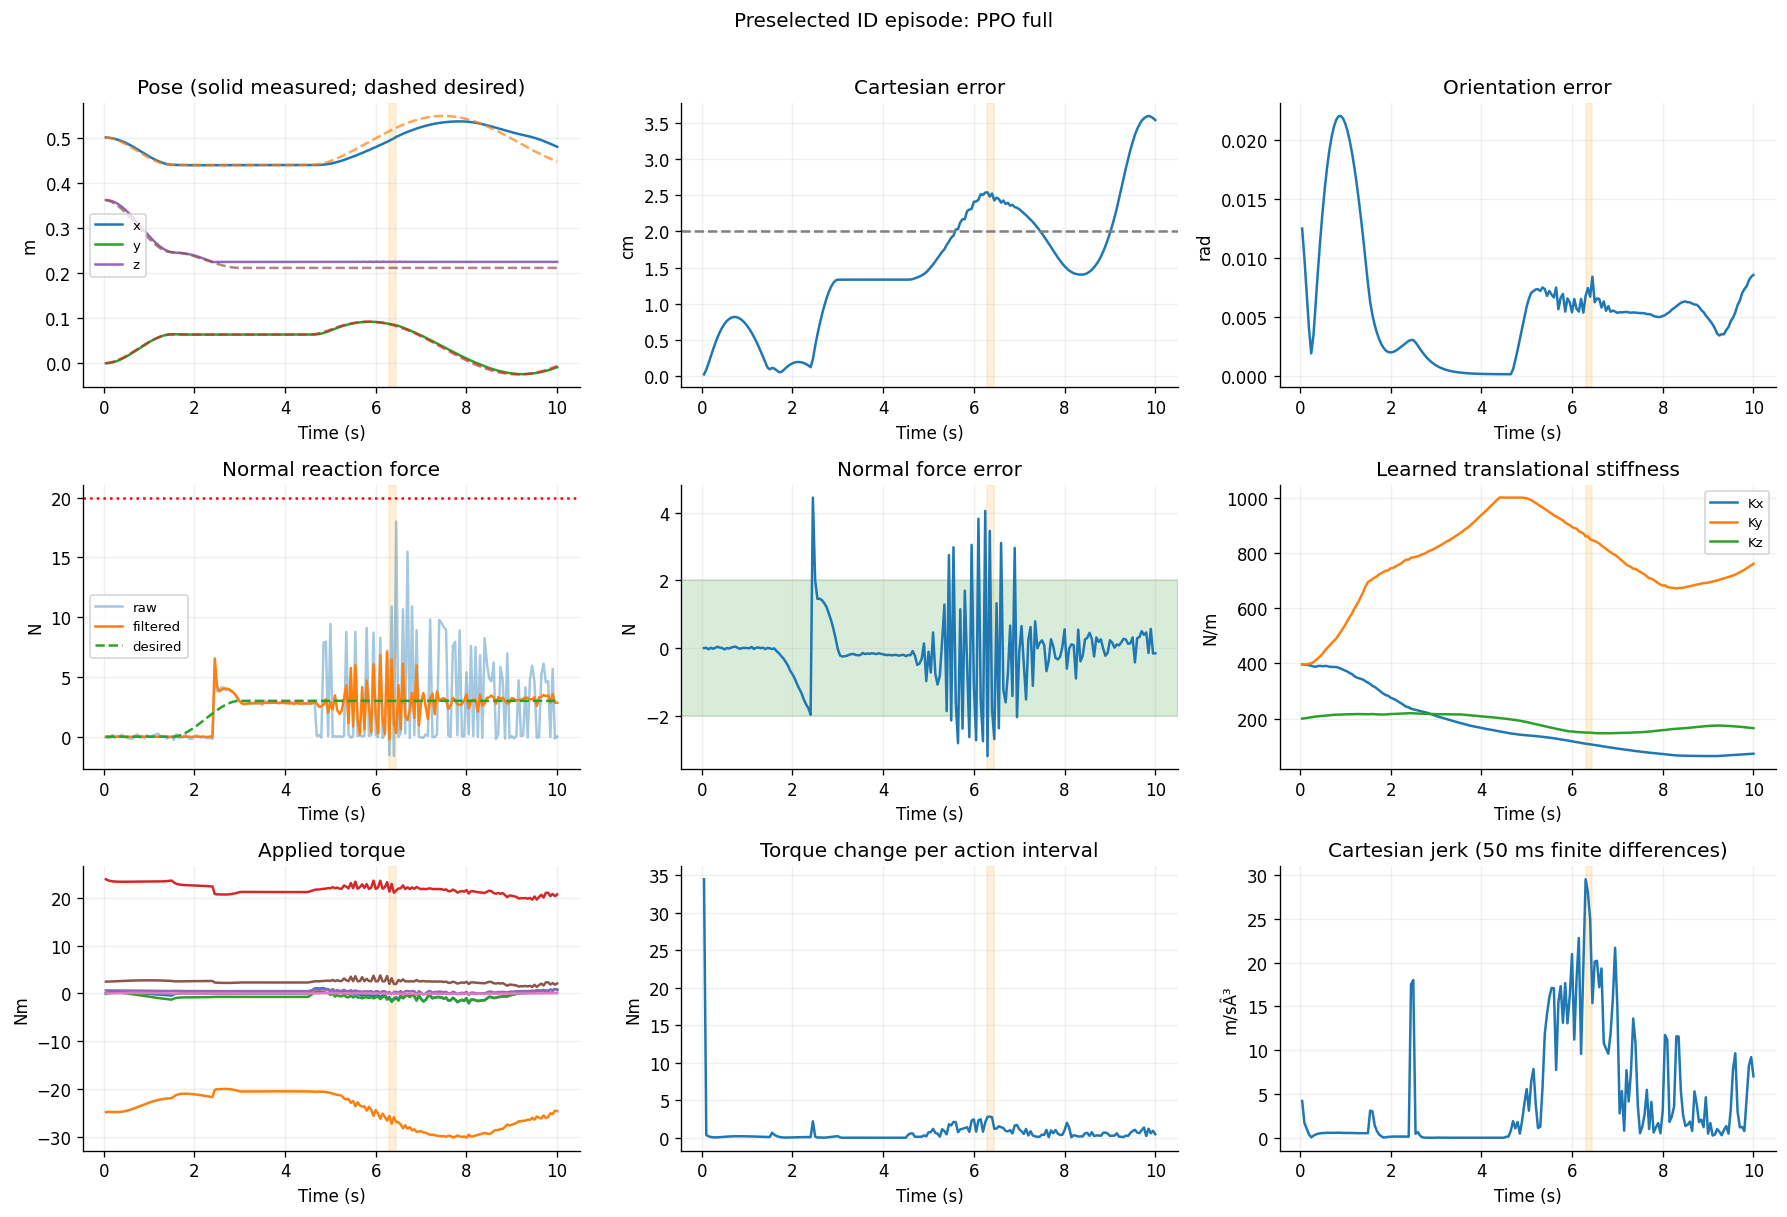

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


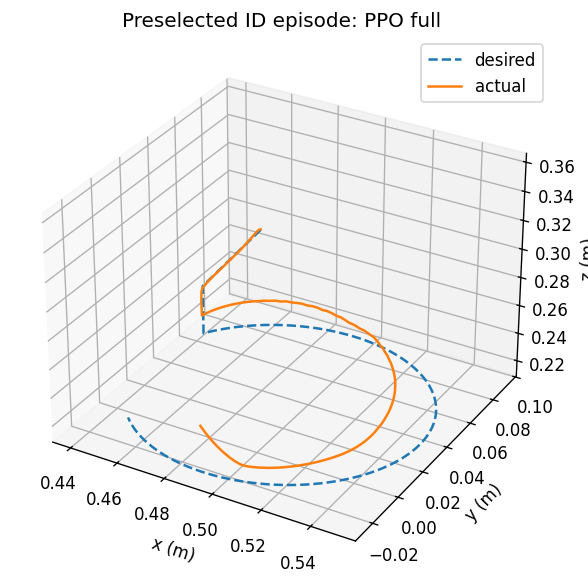

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


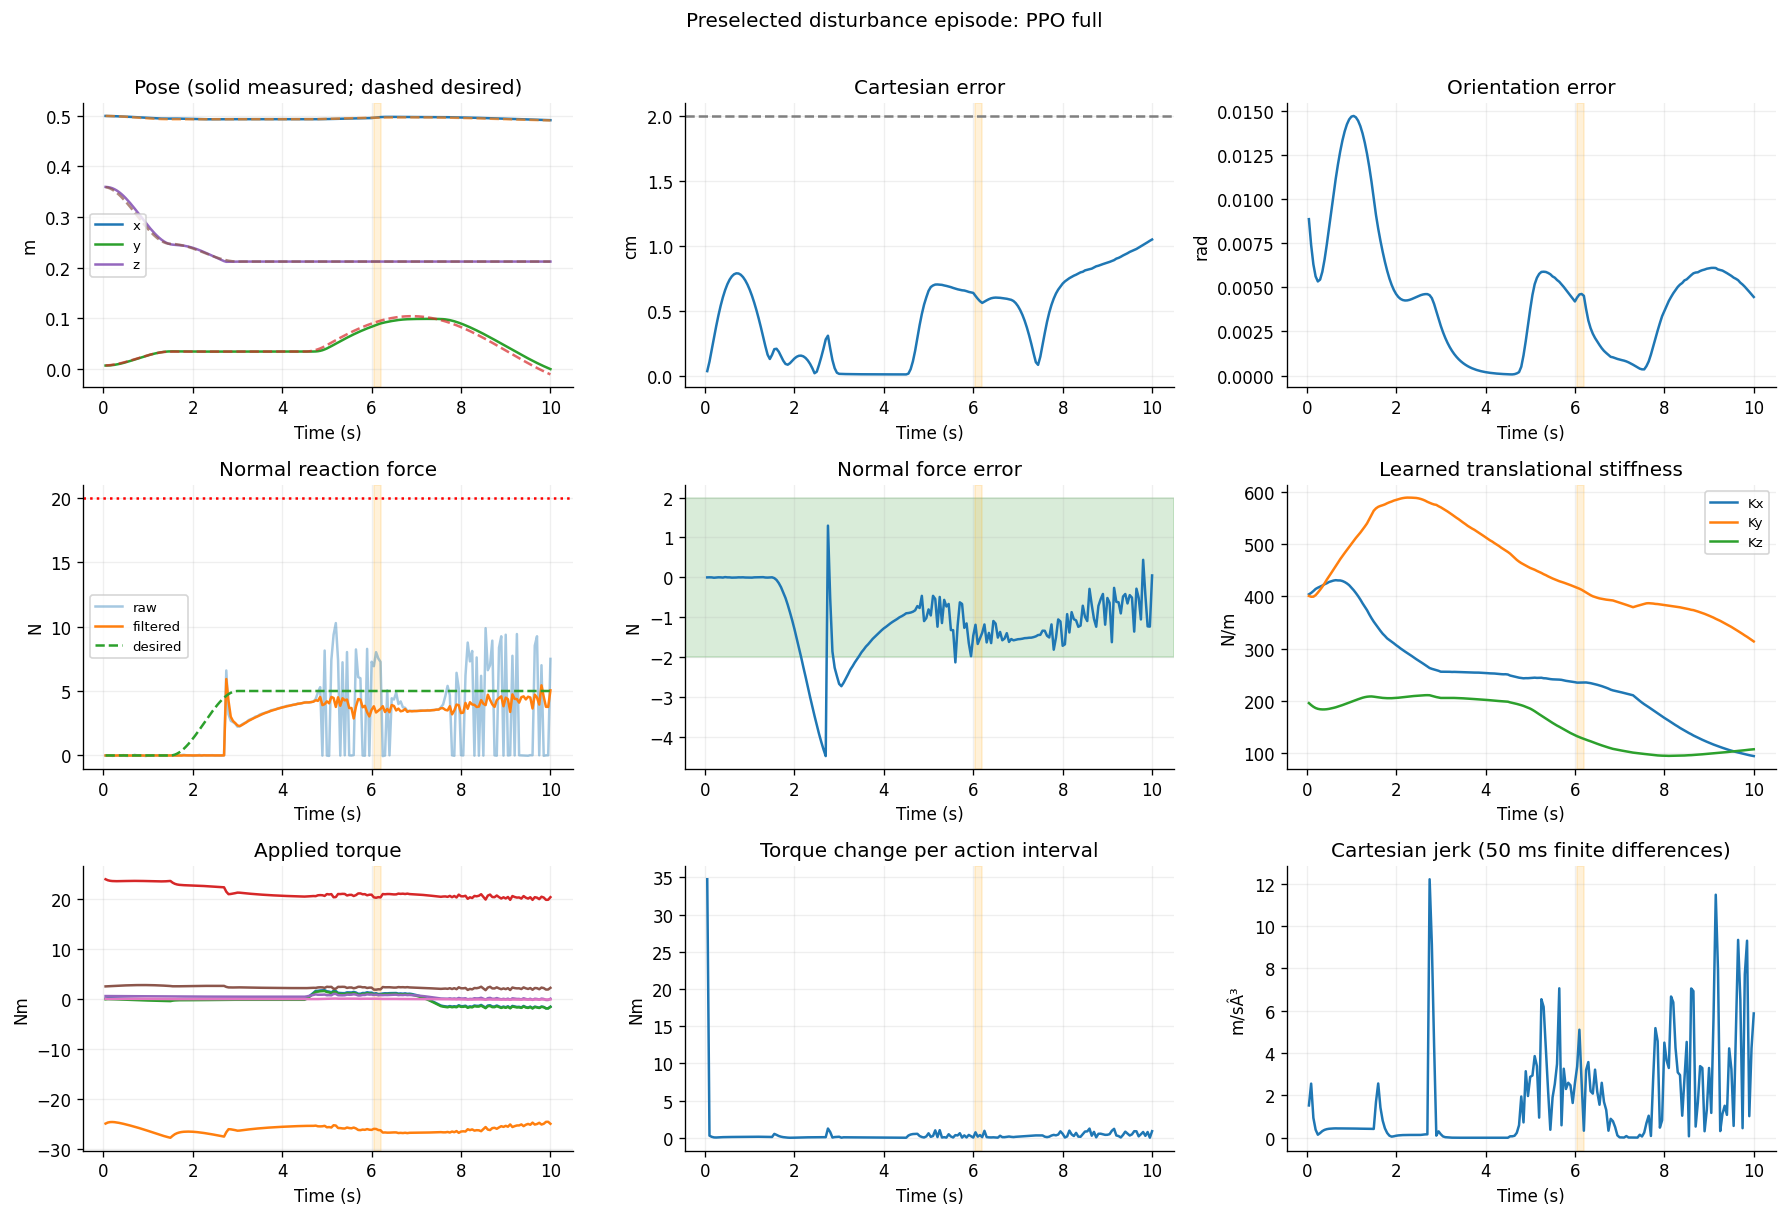

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


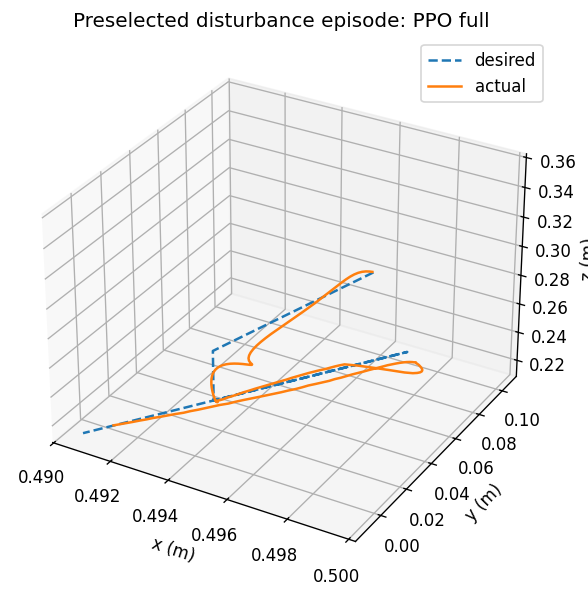

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


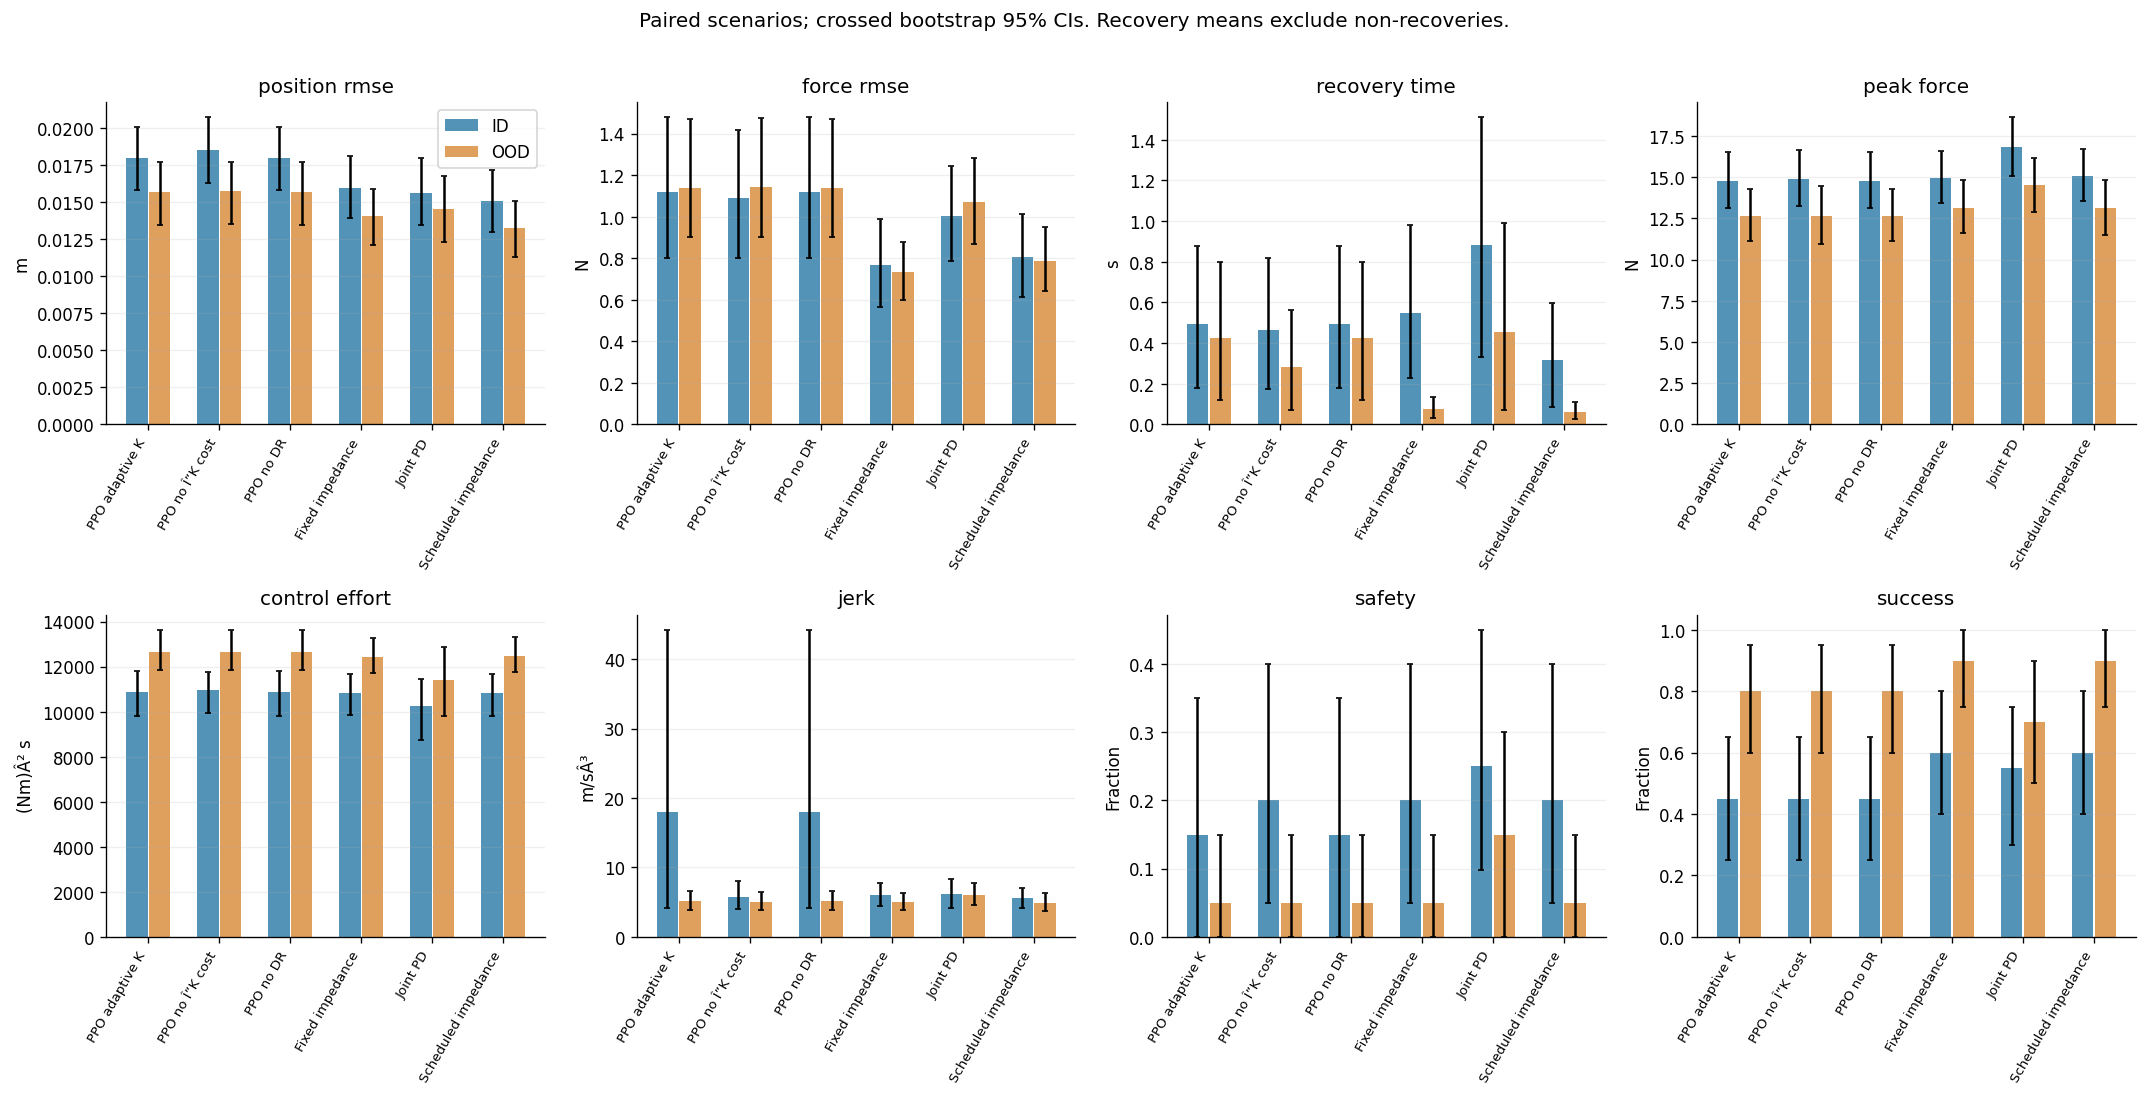

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


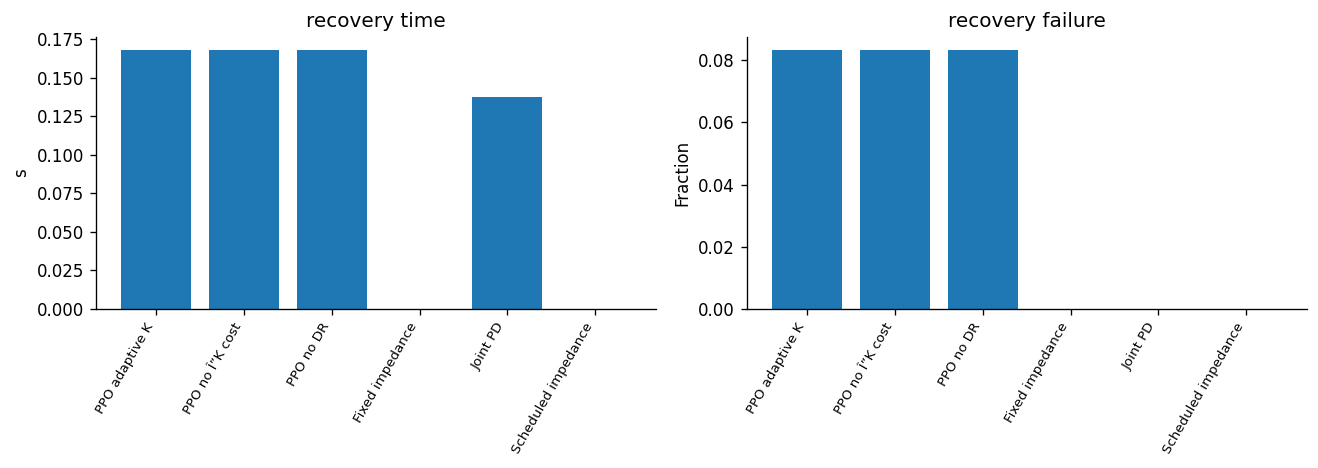

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


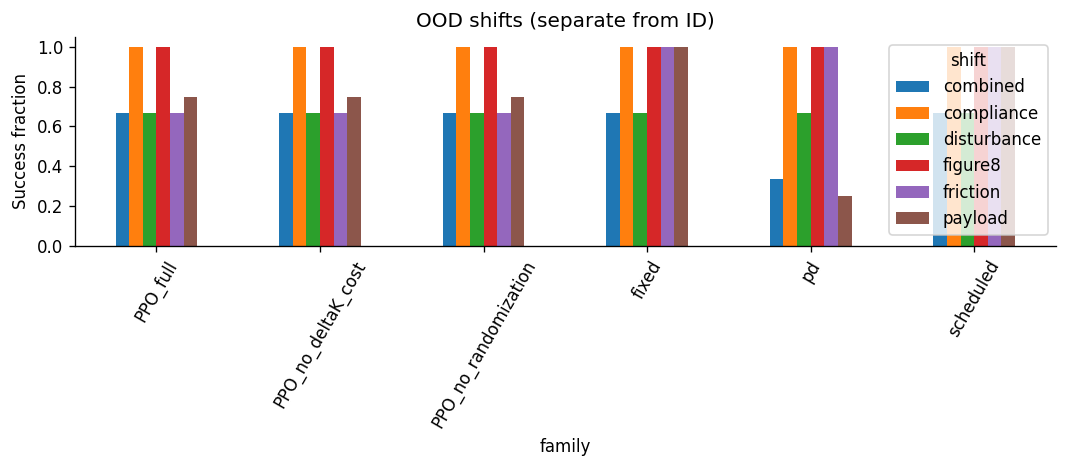

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':220,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
def savefig(fig,name):
    fig.tight_layout(); fig.savefig(OUT/'plots'/f'{name}.png',bbox_inches='tight')
    fig.savefig(OUT/'plots'/f'{name}.pdf',bbox_inches='tight'); plt.show(); plt.close(fig)

fig,axes=plt.subplots(2,3,figsize=(14,7))
for (variant,seed),directory in RUNS.items():
    file=directory/'episodes.jsonl'
    if not file.exists(): continue
    log=pd.read_json(file,lines=True); window=max(1,min(20,len(log)//4)); label=f'{variant}/{seed}'
    for ax,key,title in zip(axes.flat[:4],['return_','success','stage','safety'],['Episodic reward','Training success','Curriculum stage','Safety termination']):
        ax.plot(log.steps,log[key].rolling(window,min_periods=1).mean(),label=label); ax.set(title=title,xlabel='Policy transitions')
    if variant=='full' and seed==PLAN['seeds'][0]:
        for key in ['position','force','orientation','velocity','effort','jerk','deltaK','soft_safety','terminal']:
            axes[1,1].plot(log.steps,log['reward_'+key].rolling(window,min_periods=1).mean(),label=key)
        state=json.loads((directory/'curriculum.json').read_text())
        val=pd.DataFrame(state['validations'])
        axes[1,2].plot(val.steps,val.robust_success,'o-',label='robust validation')
axes[0,0].legend(fontsize=7); axes[1,1].legend(fontsize=7,ncol=2)
axes[1,1].set(title='Mean weighted reward components',xlabel='Policy transitions')
axes[1,2].set(title='Held-out validation success',xlabel='Policy transitions',ylim=(-.05,1.05))
savefig(fig,'training')

def representative_plot(trace,title,name):
    t=trace.t; fig,axs=plt.subplots(3,3,figsize=(15,10))
    for i,axis in enumerate('xyz'):
        axs[0,0].plot(t,trace[f'p{i}'],label=axis); axs[0,0].plot(t,trace[f'pd{i}'],'--',alpha=.7)
        axs[1,2].plot(t,trace[f'K{i}'],label=f'K{axis}')
    axs[0,0].set(title='Pose (solid measured; dashed desired)',ylabel='m')
    axs[0,1].plot(t,trace.error*100); axs[0,1].axhline(2,color='gray',ls='--'); axs[0,1].set(title='Cartesian error',ylabel='cm')
    axs[0,2].plot(t,trace.theta); axs[0,2].set(title='Orientation error',ylabel='rad')
    axs[1,0].plot(t,trace.force_raw,alpha=.4,label='raw'); axs[1,0].plot(t,trace.force_filtered,label='filtered')
    axs[1,0].plot(t,trace.fd,'--',label='desired'); axs[1,0].axhline(cfg.force_limit,color='red',ls=':'); axs[1,0].set(title='Normal reaction force',ylabel='N')
    axs[1,1].plot(t,trace.force_error); axs[1,1].axhspan(-2,2,alpha=.15,color='green'); axs[1,1].set(title='Normal force error',ylabel='N')
    axs[1,2].set(title='Learned translational stiffness',ylabel='N/m')
    for i in range(7): axs[2,0].plot(t,trace[f'tau{i}'],label=f'joint {i+1}')
    axs[2,0].set(title='Applied torque',ylabel='Nm')
    axs[2,1].plot(t,trace.torque_change); axs[2,1].set(title='Torque change per action interval',ylabel='Nm')
    axs[2,2].plot(t,trace.jerk,label='Cartesian'); axs[2,2].set(title='Cartesian jerk (50 ms finite differences)',ylabel='m/sÂ³')
    for ax in axs.flat:
        ax.set_xlabel('Time (s)'); ax.grid(alpha=.2)
        active=trace[trace.push>0]
        if len(active): ax.axvspan(active.t.min(),active.t.max(),color='orange',alpha=.15)
    for ax in [axs[0,0],axs[1,0],axs[1,2]]: ax.legend(fontsize=8)
    fig.suptitle(title,y=1.01); savefig(fig,name)
    fig=plt.figure(figsize=(7,5)); ax=fig.add_subplot(111,projection='3d')
    ax.plot(trace.pd0,trace.pd1,trace.pd2,'--',label='desired'); ax.plot(trace.p0,trace.p1,trace.p2,label='actual')
    ax.set(xlabel='x (m)',ylabel='y (m)',zlabel='z (m)',title=title); ax.legend(); savefig(fig,name+'_3d')

primary=f'PPO_full_s{PLAN["seeds"][0]}'
rep_s=TEST_SCENARIOS['ID'][0]
rep_trace=pd.read_csv(OUT/'traces'/f'ID_{primary}_{rep_s.seed}.csv.gz')
representative_plot(rep_trace,'Preselected ID episode: PPO full','representative_ID')
dist_s=DISTURBANCE_SCENARIOS[0]
dist_trace=pd.read_csv(OUT/'traces'/f'disturbance_{primary}_{dist_s.seed}.csv.gz')
representative_plot(dist_trace,'Preselected disturbance episode: PPO full','representative_disturbance')

comparison_metrics=['position_rmse','force_rmse','recovery_time','peak_force','control_effort','jerk','safety','success']
units={'position_rmse':'m','force_rmse':'N','recovery_time':'s','peak_force':'N',
       'control_effort':'(Nm)Â² s','jerk':'m/sÂ³','safety':'Fraction','success':'Fraction'}
display_names={'pd':'Joint PD','fixed':'Fixed impedance','scheduled':'Scheduled impedance',
    'PPO_full':'PPO adaptive K','PPO_no_randomization':'PPO no DR','PPO_no_deltaK_cost':'PPO no Î”K cost',
    'PPO_adaptive_KD':'PPO K+D','PPO_direct_torque':'PPO residual torque'}
fig,axes=plt.subplots(2,4,figsize=(18,9))
families=list(SUMMARY.controller.unique()); xs=np.arange(len(families))
for ax,metric in zip(axes.flat,comparison_metrics):
    for delta,split,color in [(-.16,'ID','#2878a6'),(.16,'OOD','#d88735')]:
        sub=SUMMARY[(SUMMARY.split==split)&(SUMMARY.metric==metric)].set_index('controller').reindex(families)
        means=sub['mean'].to_numpy(float); low=sub.ci_low.to_numpy(float); high=sub.ci_high.to_numpy(float)
        ax.bar(xs+delta,means,width=.30,label=split,color=color,alpha=.8)
        good=np.isfinite(means)&np.isfinite(low)&np.isfinite(high)
        ax.errorbar(xs[good]+delta,means[good],yerr=np.maximum(0,np.vstack([means[good]-low[good],high[good]-means[good]])),fmt='none',color='black',capsize=2)
    ax.set_title(metric.replace('_',' ')); ax.set_ylabel(units[metric])
    ax.set_xticks(xs,[display_names.get(f,f) for f in families],rotation=60,ha='right',fontsize=8)
    ax.grid(axis='y',alpha=.2)
axes[0,0].legend(); fig.suptitle('Paired scenarios; crossed bootstrap 95% CIs. Recovery means exclude non-recoveries.',y=1.01)
savefig(fig,'ID_OOD_benchmark')

fig,axes=plt.subplots(1,2,figsize=(11,4))
for i,key in enumerate(['recovery_time','recovery_failure']):
    sub=SUMMARY[(SUMMARY.split=='disturbance')&(SUMMARY.metric==key)].set_index('controller').reindex(families)
    axes[i].bar(xs,sub['mean']); axes[i].set_xticks(xs,[display_names.get(f,f) for f in families],rotation=60,ha='right',fontsize=8)
    axes[i].set_ylabel('s' if key=='recovery_time' else 'Fraction')
    axes[i].set_title(key.replace('_',' '))
savefig(fig,'disturbance_recovery')
fig,ax=plt.subplots(figsize=(9,4))
ood=RESULTS[RESULTS.split=='OOD'].groupby(['family','shift']).success.mean().unstack('shift')
ood.plot.bar(ax=ax); ax.set(ylabel='Success fraction',title='OOD shifts (separate from ID)'); ax.tick_params(axis='x',rotation=60)
savefig(fig,'OOD_by_shift')

## 26. MuJoCo videos
Fixed, scheduled and PPO run the **same predetermined difficult OOD figure-eight scenario**. These three videos satisfy both the common-scenario comparison and held-out-geometry demonstration. A failed controller produces an honest shortened video, with its termination reason and metrics saved. Overlays show time, desired/measured force and all three gains. Videos are generated from real simulation states at 20 fps.

In [41]:
# Predeclared demonstration, no cherry-picking successful runs. All primary videos share one scenario.
video_s=replace(scenario(SPLIT_BASES['OOD'],'OOD',index=5),geometry='figure8')
dump_json(OUT/'configs/video_scenario.json',asdict(video_s))
for name in ['fixed','scheduled',primary]:
    method=METHODS[name]; model=norm=None
    if method['run_dir']: model,norm=load_selected(method['run_dir'])
    filename=OUT/'videos'/f'{name}_OOD_figure8.mp4'
    m,trace=rollout(video_s,method['controller'],method['params'],model,norm,extended=method['extended'],video=filename)
    trace.to_csv(OUT/'traces'/f'video_{name}.csv',index=False)
    dump_json(OUT/'videos'/f'{name}_metrics.json',m)
    if norm is not None: norm.close()
    print(name,m['termination_reason']); display(Video(str(filename),embed=True))

fixed time_limit


scheduled time_limit


PPO_full_s11 time_limit


## 27. Interpretation
We inspect stiffness by phase, force error, tangential error, payload, compliance and known disturbance onset. These feedback-system associations are not interventions and cannot establish causality. The shared force servo, changed gain-dependent damping, saturation and validation model selection may all shape the relationship. Near-constant learned stiffness is a valid negative outcome; the notebook does not label it intelligent adaptation by default.

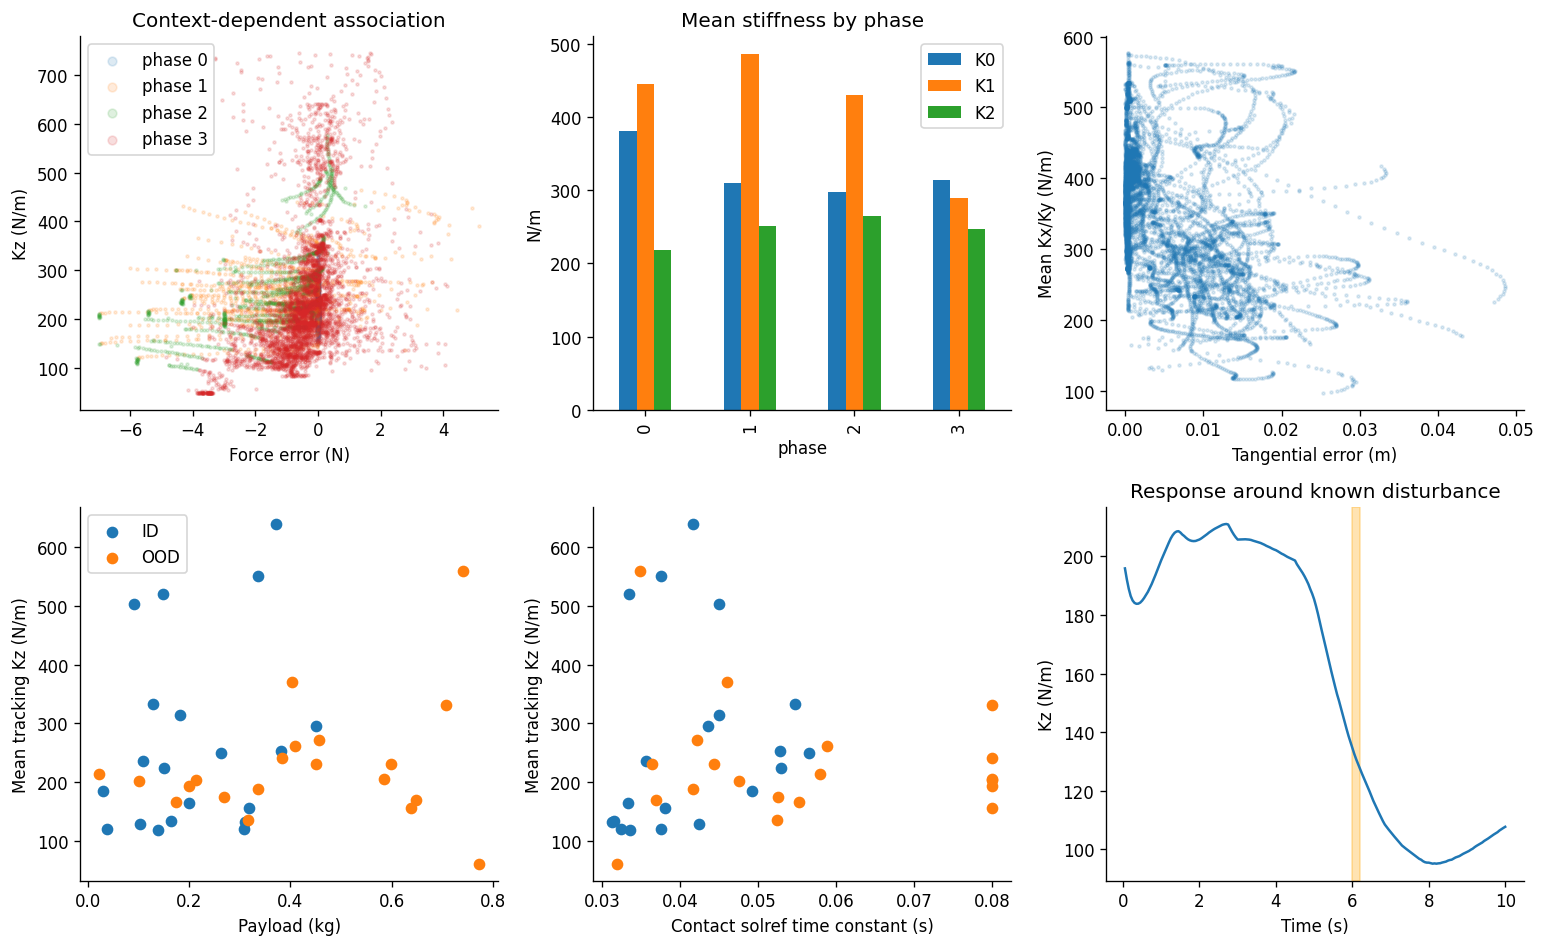

These are descriptive correlations. They are not causal effects of stiffness, payload, or compliance.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,K0,K1,K2
phase,,,
0,380.962608,445.653265,218.625341
1,309.967926,486.461776,251.208673
2,297.512748,430.430280,264.237726
3,314.011003,288.951751,246.425889


In [42]:
interpretation=[]
for split in ['ID','OOD']:
    for s in TEST_SCENARIOS[split]:
        tr=pd.read_csv(OUT/'traces'/f'{split}_{primary}_{s.seed}.csv.gz')
        tr['split']=split; tr['scenario']=s.seed
        tr['tangential_error']=np.hypot(tr.pd0-tr.p0,tr.pd1-tr.p1)
        interpretation.append(tr)
INTERPRET=pd.concat(interpretation,ignore_index=True)
features=['K0','K1','K2','force_error','tangential_error','payload','compliance','push']
correlations=INTERPRET[features].corr(method='spearman')
correlations.to_csv(OUT/'metrics/interpretability_spearman.csv')
fig,axes=plt.subplots(2,3,figsize=(13,8))
for phase,g in INTERPRET.groupby('phase'): axes[0,0].scatter(g.force_error,g.K2,s=3,alpha=.15,label=f'phase {phase}')
axes[0,0].set(xlabel='Force error (N)',ylabel='Kz (N/m)',title='Context-dependent association'); axes[0,0].legend(markerscale=3)
INTERPRET.groupby('phase')[['K0','K1','K2']].mean().plot.bar(ax=axes[0,1]); axes[0,1].set(title='Mean stiffness by phase',ylabel='N/m')
axes[0,2].scatter(INTERPRET.tangential_error,(INTERPRET.K0+INTERPRET.K1)/2,s=3,alpha=.15)
axes[0,2].set(xlabel='Tangential error (m)',ylabel='Mean Kx/Ky (N/m)')
episode_means=INTERPRET[INTERPRET.phase==3].groupby(['scenario','split'])[['K2','payload','compliance']].mean().reset_index()
for split,g in episode_means.groupby('split'):
    axes[1,0].scatter(g.payload,g.K2,label=split); axes[1,1].scatter(g.compliance,g.K2,label=split)
axes[1,0].set(xlabel='Payload (kg)',ylabel='Mean tracking Kz (N/m)'); axes[1,0].legend()
axes[1,1].set(xlabel='Contact solref time constant (s)',ylabel='Mean tracking Kz (N/m)')
axes[1,2].plot(dist_trace.t,dist_trace.K2,label='Kz'); axes[1,2].axvspan(dist_s.push_start,dist_s.push_start+.2,color='orange',alpha=.3)
axes[1,2].set(xlabel='Time (s)',ylabel='Kz (N/m)',title='Response around known disturbance')
savefig(fig,'interpretability')
print('These are descriptive correlations. They are not causal effects of stiffness, payload, or compliance.')
phase_means=INTERPRET.groupby('phase')[['K0','K1','K2']].mean(); display(phase_means)

## 28. Limitations
* Simulated contact compliance is solver-defined and uncalibrated; real materials, sensor latency, friction hysteresis and actuator bandwidth differ.
* Only the probe collides with the task surface. This does not benchmark whole-arm collision avoidance.
* The controller knows randomized inertial parameters through MuJoCo's mass model; unknown-model robustness is not established. Sensor compensation is idealized.
* Diagonal inertia-based damping and regularized null-space projection are practical approximations. Time-varying stiffness has no passivity guarantee or energy tank; safety bounds and tests are empirical guards.
* The normal-force servo is shared by all primary methods. Results address the incremental value of gain adaptation within that architecture, not pure force-free impedance control.
* Fixed observation normalization and nominal-world position targets can expose height-dependent tracking/force tradeoffs. Policy memory is limited to current observations and previous action; no recurrent estimator is trained.
* Early terminations censor continuous metrics. Safety rates, completion, missing counts and recovery failures must accompany conditional averages. Jerk and torque variation use policy-rate samples; effort and work proxies integrate at physics rate.
* OOD geometry and parameter shifts are deliberate stress tests, not proof of generalization to arbitrary tasks. Simulation success is not evidence of safe hardware transfer.
* The runtime presets are finite sample budgets. If validation does not improve or curriculum advances mostly by timeout, report undertraining and run longer; do not claim convergence.

## 29. Conclusions from measured results
The following report is computed from the actual saved evaluation outcomes. It reports numerical differences without assuming superiority. Practical relevance should be assessed against the 2 cm/2 N tolerances and safety outcomes, not statistical intervals alone.

In [43]:
TOTAL_SECONDS=time.perf_counter()-PROJECT_STARTED
lines=[f'Mode: {cfg.mode}. Training seeds: {PLAN["seeds"]}. Steps per run: {PLAN["steps"]}.',
       f'Training wall time this session: {TRAINING_SECONDS/60:.1f} minutes.',
       f'Total project wall time this session, excluding installation: {TOTAL_SECONDS/60:.1f} minutes.',
       'No superiority claim is assumed. Paired deltas below are full PPO minus comparator.',
       'Continuous metrics are conditional on observed data; always inspect completion, missing counts, and safety failures.']
for split,comp,metric,hyp in [('ID','fixed','position_rmse','H1 tracking'),('ID','fixed','force_rmse','H1 force'),
    ('disturbance','fixed','recovery_time','H2 recovery'),('OOD','PPO_no_randomization','success','H3 robustness')]:
    r=PAIRED[(PAIRED.split==split)&(PAIRED.comparator==comp)&(PAIRED.metric==metric)].iloc[0]
    lines.append(f'{hyp}: delta={r["mean"]:.4g}, 95% CI [{r.ci_low:.4g}, {r.ci_high:.4g}], n={r.n}.')
if cfg.mode=='extended' and cfg.extended_experiments:
    for metric in ['safety','jerk']:
        r=PAIRED[(PAIRED.split=='OOD')&(PAIRED.comparator=='PPO_direct_torque')&(PAIRED.metric==metric)].iloc[0]
        lines.append(f'H4 OOD {metric}: delta={r["mean"]:.4g}, CI [{r.ci_low:.4g}, {r.ci_high:.4g}].')
lines+=['H4 is evaluated only when extended direct-torque runs are present; inspect matched-budget learning curves.',
        'H5: phase/force/stiffness associations are plotted; interpretation must consider force-servo and policy feedback.',
        'Debug estimates are pipeline diagnostics, not research evidence. Three or five seeds still provide limited seed-level precision.',
        'Recovery times exclude censored/non-recovering trials; recovery-failure rate must be reported alongside them.']
text_report='\n'.join(lines); print(text_report)
(OUT/'metrics/results_interpretation.txt').write_text(text_report)
dump_json(OUT/'configs/completion.json',dict(completed=True,mode=cfg.mode,training_seconds=TRAINING_SECONDS,
    project_seconds_this_session=TOTAL_SECONDS,
    validation_passed=VALIDATION_PASSED,versions={p:__import__(p).__version__ for p in ['mujoco','gymnasium','stable_baselines3','torch','numpy']}))

Mode: standard. Training seeds: [11]. Steps per run: 32768.
Training wall time this session: 39.7 minutes.
Total project wall time this session, excluding installation: 80.9 minutes.
No superiority claim is assumed. Paired deltas below are full PPO minus comparator.
Continuous metrics are conditional on observed data; always inspect completion, missing counts, and safety failures.
H1 tracking: delta=0.001977, 95% CI [0.0004405, 0.003589], n=20.
H1 force: delta=0.3511, 95% CI [0.1308, 0.6432], n=20.
H2 recovery: delta=0.1682, 95% CI [0, 0.4042], n=11.
H3 robustness: delta=0, 95% CI [0, 0], n=20.
H4 is evaluated only when extended direct-torque runs are present; inspect matched-budget learning curves.
H5: phase/force/stiffness associations are plotted; interpretation must consider force-servo and policy feedback.
Debug estimates are pipeline diagnostics, not research evidence. Three or five seeds still provide limited seed-level precision.
Recovery times exclude censored/non-recovering t

## 30. Saved artifacts and reproduction
Outputs are organized as `outputs/<mode>/{checkpoints,logs,metrics,plots,videos,configs,traces}` (or the optional Drive root). Keep `config.json`, asset manifest/commit, scenario manifests, best-checkpoint directory **and its normalize.pkl**, episode CSVs, paired-effect tables and failure counts together.

To reproduce: open this notebook in a fresh Colab runtime, choose the same mode/configuration, Run all. To resume: preserve the output tree and rerun with `resume=True`; latest weights, optimizer, normalization and curriculum are restored at an episode boundary. To perform an independent new run, choose a fresh output root or turn resumption off. Never tune gains or change architecture after examining test outcomes and continue calling those same test seeds untouched.

All source code required to execute is embedded in this notebook. Downloads are restricted to pinned public packages and Panda assets. MuJoCo Menagerie's Panda license is downloaded alongside its assets. No local development scripts or uploaded dataset are needed.

In [44]:
print('Important artifacts:')
for directory in ['configs','metrics','plots','videos','checkpoints','traces']:
    files=list((OUT/directory).rglob('*')); print(f'{(OUT/directory).resolve()}: {sum(p.is_file() for p in files)} files')
print('Episode CSV:',(OUT/'metrics/episodes.csv').resolve())
print('Numerical summary:',(OUT/'metrics/summary_numeric.csv').resolve())
print('Paired effects:',(OUT/'metrics/paired_effects.csv').resolve())

Important artifacts:
/content/outputs/standard/configs: 14 files
/content/outputs/standard/metrics: 14 files
/content/outputs/standard/plots: 19 files
/content/outputs/standard/videos: 6 files
/content/outputs/standard/checkpoints: 375 files
/content/outputs/standard/traces: 316 files
Episode CSV: /content/outputs/standard/metrics/episodes.csv
Numerical summary: /content/outputs/standard/metrics/summary_numeric.csv
Paired effects: /content/outputs/standard/metrics/paired_effects.csv
